# Sen-2 LULC India — Pre-flood LULC Semantic Segmentation (Parts 1 & 2) — SAM 2.1 (Hiera-B+) edition

**Purpose.** Train and rigorously evaluate seven-class LULC *semantic segmentation* models on the official **Sen-2 LULC** dataset
(Sawant et al., Data in Brief 2023, DOI `10.1016/j.dib.2023.109724`; data DOI `10.17632/f4ky6ks248.3`), to produce a pre-flood Sentinel-2 LULC layer
for later intersection with a Sentinel-1 flood mask (**flood exposure by pre-existing land cover — not LULC change detection**).

**Model trained here: SAM 2.1 with the official Hiera-B+ image encoder** (`facebookresearch/sam2`; Ravi et al., ICLR 2025, arXiv:2408.00714) + a light multi-scale semantic head. SAM's prompt-based mask decoder is not used (it is class-agnostic). The notebook is configured for *Run All* (Accelerator = GPU T4 x2, Internet = ON).

**This notebook = Part 1 (dataset) + Part 2 (training).** Part 3 (GeoTIFF inference, area statistics, flood-exposure utilities) and Part 4
(RS3Mamba / Samba / SAM_RS / SaSAM / SAM-2 adapters, multi-seed statistics, Bangladesh fine-tuning) are delivered separately.

**What was verified before writing this notebook (official Mendeley pages):** Version 3 is the latest (DOI `10.17632/f4ky6ks248.3`); RGB = B4/B3/B2, 10 m, Sentinel-2 L2A, Feb–Mar 2021, Central India;
image/mask folders for train/test/validate. **Not verifiable from outside Kaggle:** exact file names, sizes, licence text, API/download URLs, final sample count.
Therefore every such fact is **discovered and logged at run time**, and nothing downstream hardcodes folder names, mask encoding or image size.

**Scientific constraints respected:** RGB only (`INPUT_CHANNELS=3`); source label 0 = Unclassified is *ignored* (never Water); labels 1–7 → model ids 0–6; official split is used as-is; normalisation statistics come from the training split only;
the test split is touched only by the explicit `--mode test` run after model selection.

**Runtime order:** *Settings → Accelerator = GPU T4 x2, Internet = ON.* Run cells top to bottom.

## 1. Kaggle environment verification

In [1]:
import os, sys, json, time, shutil, platform, subprocess, random, datetime, re, hashlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

ROOT = "/kaggle/working/lulc_research"
for d in ["official_dataset","dataset_analysis","splits","preprocessing","experiments","model_comparisons",
          "real_world_inference","flood_exposure_ready","reproducibility","paper_tables","code"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
os.environ["LULC_ROOT"] = ROOT
SEED = 42
random.seed(SEED); np.random.seed(SEED)
RUN_STARTED = datetime.datetime.now().isoformat(timespec="seconds")

print("Python", platform.python_version(), "|", platform.platform())
print(subprocess.run(["nvidia-smi","--query-gpu=index,name,memory.total,driver_version","--format=csv"],capture_output=True,text=True).stdout)
import torch
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| visible GPUs:", torch.cuda.device_count())
print("NOTE: two visible GPUs are NOT proof of dual-GPU training - Part 2 verifies per-rank work explicitly.")
print("CPU cores:", os.cpu_count())
du = shutil.disk_usage("/kaggle/working"); print(f"/kaggle/working free: {du.free/2**30:.1f} GiB of {du.total/2**30:.1f} GiB")

import requests
try:
    r = requests.get("https://data.mendeley.com", timeout=15); INTERNET_OK = r.status_code < 500
    print("Internet/Mendeley reachable:", INTERNET_OK, "(HTTP", r.status_code, ")")
except Exception as e:
    INTERNET_OK = False; print("Mendeley NOT reachable ->", repr(e), "\nEnable Settings > Internet, or use the manual-attachment fallback below.")

Python 3.13.15 | Linux-6.18.48+-x86_64-with-glibc2.39
index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04

torch 2.11.0+cu128 | CUDA 12.8 | visible GPUs: 2
NOTE: two visible GPUs are NOT proof of dual-GPU training - Part 2 verifies per-rank work explicitly.
CPU cores: 4
/kaggle/working free: 18.0 GiB of 19.5 GiB
Internet/Mendeley reachable: True (HTTP 403 )


## 2. Dependency installation
Only *adds* packages; PyTorch/CUDA are never replaced.

In [2]:
!pip install -q segmentation-models-pytorch timm rasterio 2>&1 | tail -2
import segmentation_models_pytorch as smp, timm, rasterio, transformers, cv2
print("smp", smp.__version__, "| timm", timm.__version__, "| rasterio", rasterio.__version__, "| transformers", transformers.__version__, "| cv2", cv2.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.7 MB/s eta 0:00:00
smp 0.5.0 | timm 1.0.29 | rasterio 1.5.1 | transformers 5.16.1 | cv2 4.14.0


### 2.1 SAM 2.1 (official `facebookresearch/sam2`) + pretrained Hiera-B+ checkpoint
Requires *Internet = ON*. Reference: Ravi et al., *SAM 2: Segment Anything in Images and Videos*, ICLR 2025, arXiv:2408.00714; Hiera: Ryali et al., ICML 2023, arXiv:2306.00989.

In [3]:
# SAM 2.1 (official facebookresearch/sam2). --no-deps so PyTorch/CUDA are NEVER replaced (sam2 needs torch >= 2.5.1: check below).
!pip install -q --no-deps "git+https://github.com/facebookresearch/sam2.git"
!pip install -q hydra-core iopath
import urllib.request, torch
assert tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2]) >= (2, 5), f"SAM 2 needs torch>=2.5.1, found {torch.__version__}"
SAM_CK_DIR = f"{ROOT}/code/sam_ckpt"; os.makedirs(SAM_CK_DIR, exist_ok=True)
SAM_CKPT = f"{SAM_CK_DIR}/sam2.1_hiera_base_plus.pt"
if not os.path.exists(SAM_CKPT):
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt", SAM_CKPT)
import sam2; print("sam2 import OK | checkpoint:", SAM_CKPT, f"{os.path.getsize(SAM_CKPT)/2**20:.0f} MiB")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 597.7 kB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 7.6 MB/s eta 0:00:00
sam2 import OK | checkpoint: /kaggle/working/lulc_research/code/sam_ckpt/sam2.1_hiera_base_plus.pt 309 MiB


In [1]:
import subprocess, shutil, os, glob, torch
ROOT = "/kaggle/working/lulc_research"
print(subprocess.run("du -h --max-depth=2 /kaggle/working | sort -h | tail -25", shell=True, capture_output=True, text=True).stdout)

KEEP = "sam2_semantic_hiera_bplus_seed42_20261013_035848"       # the run you are resuming
for d in glob.glob(f"{ROOT}/experiments/*/"):
    n = os.path.basename(d.rstrip("/"))
    if n == KEEP: continue
    if any(t in n for t in ("_smokecfg", "_ddpsmoke", "_resumetest")): shutil.rmtree(d)   # test artefacts
    else: shutil.rmtree(f"{d}checkpoints", ignore_errors=True)                            # old runs: keep csv/figures, drop weights
for p in ("/kaggle/working/lulc_deploy", "/kaggle/working/lulc_deploy_bundle.zip"):
    shutil.rmtree(p, ignore_errors=True) if os.path.isdir(p) else (os.path.exists(p) and os.remove(p))
subprocess.run("pip cache purge", shell=True)
print("free GiB:", shutil.disk_usage("/kaggle/working").free / 2**30)

# verify the checkpoints you want to resume from are not corrupt
for f in ("latest.pt", "best.pt"):
    try:
        ck = torch.load(f"{ROOT}/experiments/{KEEP}/checkpoints/{f}", map_location="cpu", weights_only=False)
        print(f, "OK, epoch", ck["epoch"] + 1); del ck
    except Exception as e:
        print(f, "CORRUPT:", repr(e))

12K	/kaggle/working/lulc_research/official_dataset
12K	/kaggle/working/lulc_research/reproducibility
24K	/kaggle/working/lulc_research/preprocessing
100K	/kaggle/working/.virtual_documents
39M	/kaggle/working/lulc_research/splits
66M	/kaggle/working/lulc_research/dataset_analysis
309M	/kaggle/working/lulc_research/code
19G	/kaggle/working/lulc_research/experiments
20G	/kaggle/working
20G	/kaggle/working/lulc_research



Files removed: 0
free GiB: 17.32479476928711
latest.pt OK, epoch 11
best.pt CORRUPT: RuntimeError('PytorchStreamReader failed reading zip archive: failed finding central directory. This is an internal miniz error. If you are seeing this error, there is a high likelihood that your checkpoint file is corrupted. This can happen if the checkpoint was not saved properly, was transferred incorrectly, or the file was modified after saving.')


In [5]:
p = f"{ROOT}/code/train.py"; s = open(p).read()
old = '''            torch.save(state, f"{ck_dir}/latest.pt")
            if improved: torch.save(state, f"{ck_dir}/best.pt")'''
new = '''            def _atomic_save(obj, path):
                tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
            if improved:
                slim = {k: state[k] for k in ("model", "epoch", "best_score", "best_epoch", "cfg", "model_meta", "label_mapping", "normalization")}
                _atomic_save(slim, f"{ck_dir}/best.pt")
            _atomic_save(state, f"{ck_dir}/latest.pt")'''
assert old in s; open(p, "w").write(s.replace(old, new)); print("patched")

patched


## 3. Shared I/O module (`io_utils.py`)
One reader/label-mapping implementation used by dataset scanning **and** training, so Part 1 statistics and Part 2 training can never disagree.

In [4]:
%%writefile /kaggle/working/lulc_research/code/io_utils.py
"""io_utils.py -- image/mask readers and label mapping shared by Part 1 (scan) and Part 2 (training).
Source labels (official): 0=Unclassified, 1..7 = 7 LULC classes.  Model labels: 0..6, 255 = ignore.
"""
import os
import numpy as np
from PIL import Image

NUM_CLASSES = 7
IGNORE_INDEX = 255
CLASS_NAMES_SRC = {1: "Water Bodies", 2: "Dense Forest", 3: "Built up", 4: "Agriculture land",
                   5: "Barren land", 6: "Fallow land", 7: "Sparse Forest"}
MODEL_CLASS_NAMES = [CLASS_NAMES_SRC[i] for i in range(1, 8)]

# source id -> model id.  source 0 (Unclassified) and anything unexpected -> IGNORE_INDEX
LUT_SRC2MODEL = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for _s in range(1, 8):
    LUT_SRC2MODEL[_s] = _s - 1
SRC_FROM_MODEL = np.arange(1, 8, dtype=np.uint8)   # model id k -> source id k+1


def read_image(path):
    """Return HxWx3 array (native dtype), channel order R,G,B. Original mode is NOT hidden from Part 1
    inspection (which opens the file separately)."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            arr = ds.read([1, 2, 3]).transpose(1, 2, 0)
        return arr
    im = Image.open(path)
    if im.mode != "RGB":
        im = im.convert("RGB")
    return np.asarray(im)


def read_mask_raw(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            a = ds.read()
        return a[0] if a.shape[0] == 1 else a.transpose(1, 2, 0)
    return np.asarray(Image.open(path))   # 'P' images yield palette INDICES (what we want)


def decode_mask(arr, enc):
    """Raw mask array -> uint8 array of SOURCE class ids (0..7). Unmapped colours -> 255.
    enc: {"type": "indexed"} or {"type": "rgb", "color_map": {"<packed_rgb_int>": source_id}}"""
    if arr.ndim == 3:
        if enc.get("type") == "rgb":
            a = arr.astype(np.uint32)
            packed = (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]
            out = np.full(packed.shape, 255, np.uint8)
            for k, v in enc["color_map"].items():
                out[packed == int(k)] = v
            return out
        arr = arr[..., 0]
    return np.clip(arr, 0, 255).astype(np.uint8)


def src_to_model(src):
    return LUT_SRC2MODEL[src]

Overwriting /kaggle/working/lulc_research/code/io_utils.py


## 4. Official Sen-2 LULC retrieval (Mendeley Data, Version 3)

Order of attempts: **(a)** Mendeley public API for `f4ky6ks248` v3 → list files → size/disk check → resumable download with retries → checksum/archive test;
**(b)** if that fails, the exact reason is printed and you can attach the *same official files* as a Kaggle Input (auto-detected) or set `MANUAL_DATA_DIR`.
No unofficial mirror is used.

In [5]:
from tqdm.auto import tqdm
MENDELEY_ID, DATASET_VERSION, DATASET_DOI = "f4ky6ks248", 3, "10.17632/f4ky6ks248.3"
API_BASE = "https://data.mendeley.com/public-api/datasets"
HDRS = {"Accept": "application/vnd.mendeley-public-dataset.1+json"}
OFFICIAL_DIR = f"{ROOT}/official_dataset"; DL_DIR = f"{OFFICIAL_DIR}/downloads"; EXTRACT_DIR = f"{OFFICIAL_DIR}/extracted"
os.makedirs(DL_DIR, exist_ok=True); os.makedirs(EXTRACT_DIR, exist_ok=True)

USE_OFFICIAL_DOWNLOAD = False      # set False to skip straight to a manually attached copy
MANUAL_DATA_DIR = "/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC"            

api_log = []
def api_get(url, params=None):
    try:
        r = requests.get(url, params=params, headers=HDRS, timeout=60)
        api_log.append({"url": r.url, "status": r.status_code, "content_type": r.headers.get("content-type"), "body_head": r.text[:300]})
        return r
    except Exception as e:
        api_log.append({"url": url, "error": repr(e)}); return None

def list_tree(folder_id="root", prefix=""):
    r = api_get(f"{API_BASE}/{MENDELEY_ID}/files", {"folder_id": folder_id, "version": DATASET_VERSION})
    if r is None or r.status_code != 200:
        raise RuntimeError(f"file-list request failed: {None if r is None else r.status_code} {None if r is None else r.text[:200]}")
    out = []
    for it in r.json():
        cd = it.get("content_details")
        if cd:   # a file
            out.append({"path": prefix + (it.get("filename") or it.get("name") or it["id"]), "id": it.get("id"),
                        "size": cd.get("size") or it.get("size"), "sha256": cd.get("sha256_hash"), "url": cd.get("download_url"),
                        "content_type": cd.get("content_type")})
        else:    # a folder
            out += list_tree(it["id"], prefix + it.get("name", it["id"]) + "/")
    return out

OFFICIAL_FILES, LISTING_ERROR, DATASET_META = None, None, {}
if USE_OFFICIAL_DOWNLOAD and INTERNET_OK:
    try:
        OFFICIAL_FILES = list_tree()
        m = api_get(f"{API_BASE}/{MENDELEY_ID}", {"version": DATASET_VERSION})
        if m is not None and m.status_code == 200: DATASET_META = m.json()
    except Exception as e:
        LISTING_ERROR = repr(e)
if OFFICIAL_FILES:
    lst = pd.DataFrame(OFFICIAL_FILES); display(lst)
    total = sum(int(s) for s in lst["size"].fillna(0)); print(f"Official files: {len(lst)} | total download ~ {total/2**30:.2f} GiB")
    free = shutil.disk_usage("/kaggle/working").free
    print(f"Free disk {free/2**30:.1f} GiB | need ~{total*2.2/2**30:.1f} GiB (archives + extracted copy)")
    if total*2.2 > free: print("WARNING: probably insufficient disk. Delete downloaded archives after extraction (KEEP_ARCHIVES=False) or use the manual route.")
    print("licence field in API metadata:", DATASET_META.get("data_licence") or DATASET_META.get("licence") or "not returned - read it on the Mendeley page")
else:
    print("Could not obtain the official file list.\nReason:", LISTING_ERROR or "download disabled / no internet")
    print("API log:", json.dumps(api_log[-3:], indent=1)[:1500])

Could not obtain the official file list.
Reason: download disabled / no internet
API log: []


In [6]:
import zipfile, tarfile
KEEP_ARCHIVES = True
DL_RECORDS = []

def sha256_of(p, chunk=1<<22):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def download_file(e, retries=6):
    name = e["path"].replace("/", "__"); dest = f"{DL_DIR}/{name}"; part = dest + ".part"; exp = int(e["size"]) if e.get("size") else None
    rec = {"file": e["path"], "local": dest, "expected_size": exp, "expected_sha256": e.get("sha256"), "status": None, "attempts": 0}
    if os.path.exists(dest) and (exp is None or os.path.getsize(dest) == exp):
        rec["status"] = "already_present"
    else:
        for att in range(retries):
            rec["attempts"] = att + 1
            try:
                pos = os.path.getsize(part) if os.path.exists(part) else 0
                with requests.get(e["url"], stream=True, timeout=60, headers={"Range": f"bytes={pos}-"} if pos else {}) as r:
                    if r.status_code == 416: os.replace(part, dest); rec["status"] = "downloaded"; break
                    r.raise_for_status()
                    resumed = pos > 0 and r.status_code == 206
                    total = int(r.headers.get("content-length", 0)) + (pos if resumed else 0)
                    with open(part, "ab" if resumed else "wb") as f, tqdm(total=total, initial=pos if resumed else 0, unit="B", unit_scale=True, desc=name[:40]) as pb:
                        for chunk in r.iter_content(1 << 20):
                            f.write(chunk); pb.update(len(chunk))
                if exp and os.path.getsize(part) != exp: raise IOError(f"size mismatch {os.path.getsize(part)} != {exp}")
                os.replace(part, dest); rec["status"] = "downloaded"; break
            except Exception as ex:
                rec["status"] = f"retrying: {ex!r}"; time.sleep(min(60, 3 * 2 ** att))
        if rec["status"] not in ("downloaded", "already_present"): rec["status"] = "FAILED: " + str(rec["status"])
    if rec["status"] in ("downloaded", "already_present"):
        rec["size_bytes"] = os.path.getsize(dest)
        if e.get("sha256"):
            rec["sha256_ok"] = sha256_of(dest).lower() == e["sha256"].lower()
            if not rec["sha256_ok"]: rec["status"] += " | SHA256 MISMATCH"
        if dest.lower().endswith(".zip"):
            try: rec["zip_test"] = zipfile.ZipFile(dest).testzip() is None
            except Exception as ex: rec["zip_test"] = False; rec["status"] += f" | bad zip: {ex!r}"
    return rec

DOWNLOAD_OK = False
if OFFICIAL_FILES:
    for e in OFFICIAL_FILES:
        if not e.get("url"): DL_RECORDS.append({"file": e["path"], "status": "FAILED: API gave no download_url"}); continue
        DL_RECORDS.append(download_file(e))
    man = pd.DataFrame(DL_RECORDS); man.to_csv(f"{OFFICIAL_DIR}/download_manifest.csv", index=False); display(man)
    DOWNLOAD_OK = all(str(s).startswith(("downloaded", "already_present")) and "MISMATCH" not in str(s) and "bad zip" not in str(s) for s in man["status"])
print("DOWNLOAD_OK =", DOWNLOAD_OK)
if not DOWNLOAD_OK:
    print("""
MANUAL FALLBACK (same OFFICIAL files):
 1. On a machine with internet open https://data.mendeley.com/datasets/f4ky6ks248/3 and download the dataset files.
 2. Kaggle: + Create > New Dataset, upload those exact files (zip archives can stay zipped), then Add Data to this notebook.
 3. Re-run from the next cell: the attached copy is auto-detected (or set MANUAL_DATA_DIR above).""")

DOWNLOAD_OK = False

MANUAL FALLBACK (same OFFICIAL files):
 1. On a machine with internet open https://data.mendeley.com/datasets/f4ky6ks248/3 and download the dataset files.
 2. Kaggle: + Create > New Dataset, upload those exact files (zip archives can stay zipped), then Add Data to this notebook.
 3. Re-run from the next cell: the attached copy is auto-detected (or set MANUAL_DATA_DIR above).


### 4.1 Extraction & dataset-root resolution

In [7]:
def extract_all(src_dir, dst):
    done = []
    for dp, _, fns in os.walk(src_dir):
        for fn in fns:
            p = os.path.join(dp, fn); low = fn.lower(); tgt = os.path.join(dst, os.path.splitext(fn)[0])
            if low.endswith(".zip"):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    with zipfile.ZipFile(p) as z: z.extractall(tgt)
                    open(tgt + ".done", "w").close()
                done.append(p)
            elif low.endswith((".tar", ".tar.gz", ".tgz")):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    with tarfile.open(p) as t: t.extractall(tgt)
                    open(tgt + ".done", "w").close()
                done.append(p)
            elif low.endswith((".rar", ".7z")):
                if not os.path.exists(tgt + ".done"):
                    os.makedirs(tgt, exist_ok=True)
                    cmd = ["7z", "x", "-y", f"-o{tgt}", p]
                    if shutil.which("7z") is None: raise RuntimeError("7z missing: run `!apt-get install -y p7zip-full` (archive.ubuntu.com is allowed) or extract manually")
                    subprocess.run(cmd, check=True, capture_output=True); open(tgt + ".done", "w").close()
                done.append(p)
    return done

IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
def count_images(root, limit=10**9):
    n = 0
    for dp, _, fns in os.walk(root):
        n += sum(os.path.splitext(f)[1].lower() in IMG_EXT for f in fns)
        if n >= limit: break
    return n

DATA_ROOT, DATA_SOURCE = None, None
if MANUAL_DATA_DIR: DATA_ROOT, DATA_SOURCE = MANUAL_DATA_DIR, "manual_data_dir"
elif DOWNLOAD_OK: DATA_ROOT, DATA_SOURCE = EXTRACT_DIR, "official_mendeley_download"
else:
    cands = []
    for dp, dn, fns in os.walk("/kaggle/input"):
        depth = dp.count(os.sep) - "/kaggle/input".count(os.sep)
        if depth <= 1 and (any(f.lower().endswith((".zip", ".tar", ".tgz", ".rar", ".7z")) for f in fns) or depth == 1): cands.append(dp)
    print("Candidate attached inputs:", cands)
    if cands: DATA_ROOT, DATA_SOURCE = "/kaggle/input", "attached_kaggle_input (verify it is the OFFICIAL Mendeley v3 files)"
if DATA_ROOT is None: raise SystemExit("No dataset available: fix the download or attach the official files, then re-run this cell.")

if DATA_ROOT != "/kaggle/input" or any(f.lower().endswith((".zip",".rar",".7z",".tar",".tgz")) for _,_,fs in os.walk(DATA_ROOT) for f in fs):
    src = DL_DIR if DATA_SOURCE.startswith("official") else DATA_ROOT
    print("Extracting archives found in", src, "..."); t0 = time.time(); extract_all(src, EXTRACT_DIR); print(f"done in {time.time()-t0:.0f}s")
    if count_images(EXTRACT_DIR, 100) > 0: DATA_ROOT = EXTRACT_DIR
if DOWNLOAD_OK and not KEEP_ARCHIVES: shutil.rmtree(DL_DIR, ignore_errors=True)
print("DATA_ROOT:", DATA_ROOT, "| source:", DATA_SOURCE)

Extracting archives found in /kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC ...
done in 448s
DATA_ROOT: /kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC | source: manual_data_dir


## 5. Dataset structure discovery & image–mask pairing
Folder roles are inferred from names, **printed for you to check**, and can be overridden with `DIR_OVERRIDE`. Nothing is assumed silently.

In [8]:
from collections import defaultdict
groups = defaultdict(list)
for dp, _, fns in os.walk(DATA_ROOT):
    imgs = [f for f in fns if os.path.splitext(f)[1].lower() in IMG_EXT]
    if imgs: groups[dp] = imgs

def classify(rel):
    toks = re.split(r"[^a-z0-9]+", rel.lower())
    kind = "mask" if any(t.startswith(("mask", "label", "gt", "annot", "msk")) for t in toks) else "image"
    sp = {s for s, pre in (("train", "train"), ("validation", "val"), ("test", "test")) if any(t.startswith(pre) for t in toks)}
    return (sp.pop() if len(sp) == 1 else None), kind

rows = []
for dp, f in sorted(groups.items()):
    rel = os.path.relpath(dp, DATA_ROOT); sp, kind = classify(rel)
    rows.append({"dir": dp, "rel": rel, "n_files": len(f), "example": f[0], "inferred_split": sp, "inferred_kind": kind})
dirs_df = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90); display(dirs_df)

# If inference is wrong/ambiguous, set e.g.  DIR_OVERRIDE = {("train","image"): ["/abs/dir"], ("train","mask"): [...], ...}
DIR_OVERRIDE = {}
roles = defaultdict(list)
if DIR_OVERRIDE: roles.update(DIR_OVERRIDE)
else:
    for r in rows:
        if r["inferred_split"]: roles[(r["inferred_split"], r["inferred_kind"])].append(r["dir"])
missing = [(s, k) for s in ("train", "validation", "test") for k in ("image", "mask") if not roles.get((s, k))]
if missing: raise SystemExit(f"Could not resolve roles {missing}. Inspect the table above and set DIR_OVERRIDE.")
for k, v in sorted(roles.items()): print(k, "->", [os.path.relpath(x, DATA_ROOT) for x in v], f"({sum(len(groups[x]) for x in v)} files)")

def norm_stem(s):
    s = s.lower()
    for t in ("_mask", "mask_", "_label", "label_", "_gt", "_msk", "-mask", "mask-"): s = s.replace(t, "")
    return s
pair_rows, unmatched = [], {}
for sp in ("train", "validation", "test"):
    imgs, msks = {}, {}; dup = 0
    for d in roles[(sp, "image")]:
        for f in groups[d]:
            k = os.path.splitext(f)[0]; dup += k in imgs; imgs[k] = os.path.join(d, f)
    for d in roles[(sp, "mask")]:
        for f in groups[d]:
            k = norm_stem(os.path.splitext(f)[0]); dup += k in msks; msks[k] = os.path.join(d, f)
    nk = {norm_stem(k): k for k in imgs}
    common = [k for k in nk if k in msks]
    for k in common: pair_rows.append({"id": f"{sp}_{nk[k]}", "split": sp, "image_path": imgs[nk[k]], "mask_path": msks[k]})
    unmatched[sp] = {"images": len(imgs), "masks": len(msks), "paired": len(common), "images_without_mask": len(imgs) - len(common),
                     "masks_without_image": len(msks) - len(common), "duplicate_stems": dup}
pairs_df = pd.DataFrame(pair_rows); display(pd.DataFrame(unmatched).T)
assert all(v["paired"] > 0 for v in unmatched.values()), "pairing failed - adapt norm_stem()/DIR_OVERRIDE"
if any(v["images_without_mask"] or v["masks_without_image"] or v["duplicate_stems"] for v in unmatched.values()):
    print("WARNING: unpaired/duplicated entries exist; only exact pairs are kept (recorded in dataset_summary.json).")

,dir,rel,n_files,example,inferred_split,inferred_kind
0,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/test_images/test,test_images/test,32079,90411.png,test,image
1,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/test_masks/test,test_masks/test,32079,202512.tif,test,mask
2,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/train_images/train,train_images/train,149600,64284.png,train,image
3,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/train_masks/train,train_masks/train,149600,23566.tif,train,mask
4,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/val_images/val,val_images/val,32079,133151.png,validation,image
5,/kaggle/input/datasets/ashrifrahman/sen2-lulc/SEN-2 LULC/val_masks/val,val_masks/val,32079,166569.tif,validation,mask


('test', 'image') -> ['test_images/test'] (32079 files)
('test', 'mask') -> ['test_masks/test'] (32079 files)
('train', 'image') -> ['train_images/train'] (149600 files)
('train', 'mask') -> ['train_masks/train'] (149600 files)
('validation', 'image') -> ['val_images/val'] (32079 files)
('validation', 'mask') -> ['val_masks/val'] (32079 files)


,images,masks,paired,images_without_mask,masks_without_image,duplicate_stems
train,149600,149600,149600,0,0,0
validation,32079,32079,32079,0,0,0
test,32079,32079,32079,0,0,0


## 6. Image & mask inspection (nothing hardcoded)

In [9]:
from PIL import Image
sys.path.insert(0, f"{ROOT}/code")
from io_utils import *
rng = np.random.RandomState(SEED); insp = []
for sp in ("train", "validation", "test"):
    sub = pairs_df[pairs_df.split == sp]; pick = sub.iloc[rng.choice(len(sub), min(300, len(sub)), replace=False)]
    for _, r in pick.iterrows():
        im = Image.open(r.image_path); ia = np.asarray(im); mk = Image.open(r.mask_path); ma = np.asarray(mk)
        insp.append(dict(split=sp, img_ext=os.path.splitext(r.image_path)[1], img_mode=im.mode, img_size=im.size, img_dtype=str(ia.dtype), img_ch=1 if ia.ndim==2 else ia.shape[2],
                         img_min=int(ia.min()), img_max=int(ia.max()), mask_mode=mk.mode, mask_size=mk.size, mask_dtype=str(ma.dtype), mask_ndim=ma.ndim,
                         mask_ch=1 if ma.ndim==2 else ma.shape[2], shape_agree=im.size==mk.size,
                         mask_unique=tuple(np.unique(ma)) if ma.ndim==2 else tuple(map(tuple, np.unique(ma.reshape(-1, ma.shape[2]), axis=0)[:20]))))
insp = pd.DataFrame(insp)
for c in ["img_ext","img_mode","img_size","img_dtype","img_ch","mask_mode","mask_size","mask_dtype","mask_ch","shape_agree"]:
    print(f"{c:12s}:", insp[c].value_counts().to_dict())
print("image value range in sample:", insp.img_min.min(), "-", insp.img_max.max())

# ---- mask encoding decision
if (insp.mask_ch == 1).all():
    vals = sorted({v for t in insp.mask_unique for v in t}); print("mask values seen (indexed raster):", vals)
    assert set(vals) <= set(range(0, 8)), f"unexpected values {vals}: compare with official documentation before continuing"
    MASK_ENC = {"type": "indexed"}
elif (insp.mask_ch >= 3).all():
    cols = sorted({tuple(c) for t in insp.mask_unique for c in t}); print("RGB mask colours seen:", cols)
    # Equal-channel colours that are 0..7 are just an indexed raster saved as 3 channels
    if all(len(set(c[:3])) == 1 and c[0] <= 7 for c in cols): MASK_ENC = {"type": "indexed"}; print("-> 3-channel but indexed (channels equal)")
    else:
        # FILL THIS from the OFFICIAL documentation (colour -> source id 0..7); do not guess.
        COLOR_MAP = {}   # e.g. {(0,0,255): 1, ...}
        if not COLOR_MAP: raise SystemExit("RGB colour masks detected: fill COLOR_MAP from the official documentation, then re-run this cell.")
        MASK_ENC = {"type": "rgb", "color_map": {str((r<<16)|(g<<8)|b): v for (r,g,b), v in COLOR_MAP.items()}}
else: raise SystemExit("Mixed mask formats - inspect `insp`.")
dt = insp.img_dtype.unique()
IMAGE_SCALE_MAX = 255.0 if list(dt) == ["uint8"] else None
if IMAGE_SCALE_MAX is None: raise SystemExit(f"Non-uint8 images {dt}: set IMAGE_SCALE_MAX from the official reflectance scaling.")
if insp.img_ch.max() != 3 or insp.img_mode.isin(["RGBA","L","P"]).any(): print("WARNING: images are not plain 3-channel RGB:", insp.img_mode.unique(), "- read_image() converts to RGB.")
sizes = insp.img_size.unique(); print("distinct image sizes in sample:", sizes)
json.dump(MASK_ENC, open(f"{ROOT}/preprocessing/mask_encoding.json", "w"), indent=2)
json.dump({"scale_max": IMAGE_SCALE_MAX, "channels": "RGB = B04,B03,B02 (per official description)", "input_channels": 3}, open(f"{ROOT}/preprocessing/image_encoding.json", "w"), indent=2)
LABEL_MAPPING = {"source_classes": {str(k): v for k, v in CLASS_NAMES_SRC.items()}, "source_unclassified": 0,
                 "source_to_model": {"0": 255, **{str(s): s-1 for s in range(1, 8)}}, "model_to_source": {str(k): k+1 for k in range(7)},
                 "ignore_index_model": 255, "model_class_names": MODEL_CLASS_NAMES}
json.dump(LABEL_MAPPING, open(f"{ROOT}/preprocessing/label_mapping.json", "w"), indent=2)
print("Saved mask_encoding.json, image_encoding.json, label_mapping.json")

img_ext     : {'.png': 900}
img_mode    : {'RGB': 900}
img_size    : {(64, 64): 900}
img_dtype   : {'uint8': 900}
img_ch      : {3: 900}
mask_mode   : {'L': 900}
mask_size   : {(64, 64): 900}
mask_dtype  : {'uint8': 900}
mask_ch     : {1: 900}
shape_agree : {True: 900}
image value range in sample: 0 - 255
mask values seen (indexed raster): [np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7)]
distinct image sizes in sample: [(64, 64)]
Saved mask_encoding.json, image_encoding.json, label_mapping.json


## 7. Full scan: integrity, shapes, per-image class pixel counts, file hashes
Every image and mask is decoded once (corrupt files are caught here). Results are cached in `dataset_inventory.csv`; re-running skips the scan. Set `SCAN_LIMIT_PER_SPLIT` to an integer **only** for a quick dry run (then delete the cached CSV).

In [10]:
from multiprocessing import Pool
SCAN_LIMIT_PER_SPLIT = None
INV_CSV = f"{ROOT}/dataset_analysis/dataset_inventory.csv"
MASK_ENC = json.load(open(f"{ROOT}/preprocessing/mask_encoding.json"))

def scan_one(a):
    i, ip, mp = a; r = {"i": i, "ok": True, "err": ""}
    try:
        im = read_image(ip); raw = read_mask_raw(mp); src = decode_mask(raw, MASK_ENC)
        r.update(img_h=im.shape[0], img_w=im.shape[1], img_c=im.shape[2], img_dtype=str(im.dtype), img_min=int(im.min()), img_max=int(im.max()),
                 mask_h=src.shape[0], mask_w=src.shape[1], shape_ok=im.shape[:2] == src.shape[:2],
                 img_md5=hashlib.md5(open(ip, "rb").read()).hexdigest(), mask_md5=hashlib.md5(open(mp, "rb").read()).hexdigest())
        cnt = np.bincount(src.ravel(), minlength=256)
        for k in range(8): r[f"m{k}"] = int(cnt[k])
        r["m_other"] = int(cnt[8:].sum())
    except Exception as e:
        r.update(ok=False, err=repr(e)[:200])
    return r

if os.path.exists(INV_CSV): inv = pd.read_csv(INV_CSV); print("Loaded cached inventory:", len(inv))
else:
    work = pairs_df if not SCAN_LIMIT_PER_SPLIT else pairs_df.groupby("split").head(SCAN_LIMIT_PER_SPLIT)
    work = work.reset_index(drop=True); t0 = time.time()
    with Pool(max(2, os.cpu_count())) as p:
        res = list(tqdm(p.imap(scan_one, [(i, r.image_path, r.mask_path) for i, r in work.iterrows()], chunksize=64), total=len(work), desc="scanning"))
    inv = work.join(pd.DataFrame(res).set_index("i")); inv.to_csv(INV_CSV, index=False); print(f"scan finished in {(time.time()-t0)/60:.1f} min")
bad = inv[~inv.ok]; print("corrupt/unreadable pairs:", len(bad)); display(bad.head())
good = inv[inv.ok].copy()
print("shape mismatches (image vs mask):", int((~good.shape_ok.astype(bool)).sum()))
print("image size distribution:", good.groupby(["img_h","img_w"]).size().to_dict()); print("image dtype:", good.img_dtype.unique(), "| channels:", good.img_c.unique())
print("masks containing ONLY unclassified(0):", int(((good[[f"m{k}" for k in range(1,8)]].sum(axis=1)) == 0).sum()))
print("masks with source values outside 0..7:", int((good.m_other > 0).sum()))
CONST_SIZE = good[["img_h","img_w"]].drop_duplicates().shape[0] == 1
print("constant image size:", CONST_SIZE, "(Part 2 trains at native resolution when constant; otherwise set CFG['input_size'])")

Loaded cached inventory: 213758
corrupt/unreadable pairs: 0


,id,split,image_path,mask_path,ok,err,img_h,img_w,img_c,img_dtype,...,mask_md5,m0,m1,m2,m3,m4,m5,m6,m7,m_other


shape mismatches (image vs mask): 0
image size distribution: {(64, 64): 213758}
image dtype: ['uint8'] | channels: [3]
masks containing ONLY unclassified(0): 0
masks with source values outside 0..7: 0
constant image size: True (Part 2 trains at native resolution when constant; otherwise set CFG['input_size'])


## 8. Official-split verification & leakage checks

In [11]:
good = good[good.shape_ok.astype(bool) & (good.m_other == 0)].copy()      # keep only clean pairs
leak = {}
for col in ("img_md5", "mask_md5"):
    g = good.groupby(col).agg(n=("id", "size"), ns=("split", "nunique"))
    leak[f"{col}_in_multiple_splits"] = int((g.ns > 1).sum()); leak[f"{col}_duplicated_within_one_split"] = int(((g.n > 1) & (g.ns == 1)).sum())
name_leak = good.assign(stem=good.image_path.map(lambda p: os.path.splitext(os.path.basename(p))[0])).groupby("stem").split.nunique()
leak["image_filename_stems_in_multiple_splits"] = int((name_leak > 1).sum())
print(json.dumps(leak, indent=1))
print("Identical IMAGE hashes across splits = true leakage. Identical MASK hashes can occur legitimately (e.g. uniform masks); inspect if non-zero.")
print("Geographic independence: this dataset ships as preprocessed patches; unless the files carry coordinates it CANNOT be verified.",
      "Coordinates present in tif metadata?", any(good.image_path.str.lower().str.endswith((".tif", ".tiff"))))
print(good.groupby("split").size().rename("clean_pairs").to_frame())

for sp, name in (("train", "train"), ("validation", "validation"), ("test", "test")):
    good[good.split == sp][["id", "image_path", "mask_path", "split"]].to_csv(f"{ROOT}/splits/{name}_manifest.csv", index=False)
print("Saved train/validation/test manifests (official split, unchanged).")

{
 "img_md5_in_multiple_splits": 0,
 "img_md5_duplicated_within_one_split": 0,
 "mask_md5_in_multiple_splits": 0,
 "mask_md5_duplicated_within_one_split": 0,
 "image_filename_stems_in_multiple_splits": 0
}
Identical IMAGE hashes across splits = true leakage. Identical MASK hashes can occur legitimately (e.g. uniform masks); inspect if non-zero.
Geographic independence: this dataset ships as preprocessed patches; unless the files carry coordinates it CANNOT be verified. Coordinates present in tif metadata? False
            clean_pairs
split                  
test              32079
train            149600
validation        32079
Saved train/validation/test manifests (official split, unchanged).


## 9. Class-imbalance analysis (training split) & class-distribution plot

,class,train_pixels,proportion,images_with_class
0,Water Bodies,6922061.0,0.011296,79291
1,Dense Forest,7654773.0,0.012492,99831
2,Built up,34805405.0,0.056801,139062
3,Agriculture land,66751970.0,0.108936,142577
4,Barren land,171948086.0,0.280612,149504
5,Fallow land,298511477.0,0.487158,149561
6,Sparse Forest,26167813.0,0.042705,128908


ignored (Unclassified) share of all train pixels: 0.000%


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


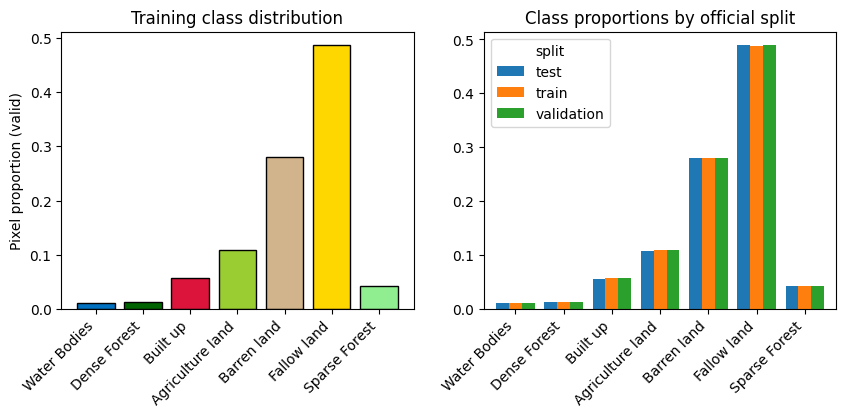

In [12]:
import matplotlib; import matplotlib.pyplot as plt
cols = [f"m{k}" for k in range(8)]
split_counts = good.groupby("split")[cols].sum()
tr = good[good.split == "train"]
px_src = tr[[f"m{k}" for k in range(1, 8)]].sum().values.astype(np.float64)           # source 1..7 == model 0..6 order
ign = int(tr.m0.sum()); valid = px_src.sum()
beta = 0.9999
stats = {"train_pixels_model_order": px_src.tolist(), "class_names_model_order": MODEL_CLASS_NAMES, "train_ignored_unclassified_pixels": ign,
         "train_ignored_fraction": ign / (ign + valid), "train_class_proportion": (px_src / valid).tolist(),
         "effective_number_beta": beta, "effective_number": ((1 - beta ** px_src) / (1 - beta)).tolist(),
         "image_level_occurrence": {MODEL_CLASS_NAMES[k]: int((tr[f"m{k+1}"] > 0).sum()) for k in range(7)}, "n_train_images": int(len(tr))}
json.dump(stats, open(f"{ROOT}/dataset_analysis/class_stats.json", "w"), indent=2)
tab = pd.DataFrame({"class": MODEL_CLASS_NAMES, "train_pixels": px_src, "proportion": px_src / valid, "images_with_class": list(stats["image_level_occurrence"].values())})
display(tab); print(f"ignored (Unclassified) share of all train pixels: {stats['train_ignored_fraction']:.3%}")
split_counts.to_csv(f"{ROOT}/dataset_analysis/class_pixels_per_split.csv")
PAL = {i: tuple(c/255 for c in ({1:(0,112,192),2:(0,100,0),3:(220,20,60),4:(154,205,50),5:(210,180,140),6:(255,215,0),7:(144,238,144)}[i])) for i in range(1, 8)}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(MODEL_CLASS_NAMES, px_src / valid, color=[PAL[i] for i in range(1, 8)], edgecolor="k"); ax[0].set_ylabel("Pixel proportion (valid)"); ax[0].set_title("Training class distribution")
plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
prop = split_counts[[f"m{k}" for k in range(1, 8)]]; prop = prop.div(prop.sum(1), axis=0)
prop.T.plot.bar(ax=ax[1], width=.8); ax[1].set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax[1].set_title("Class proportions by official split")
for ext in ("png", "eps"): fig.savefig(f"{ROOT}/dataset_analysis/class_distribution.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## 10. Training-split normalisation statistics (`normalization_stats.json`)
Computed on **training images only**, on `[0,1]`-scaled RGB. ImageNet statistics are stored separately and only used when `CFG['normalization']='imagenet'`.

In [13]:
NORM_MAX_IMAGES = 30000        # random training subset for speed; None = all training images
SCALE = json.load(open(f"{ROOT}/preprocessing/image_encoding.json"))["scale_max"]
def norm_one(p):
    a = read_image(p).astype(np.float64) / SCALE; return a.sum((0, 1)), (a ** 2).sum((0, 1)), a.shape[0] * a.shape[1]
tpaths = tr.image_path.tolist()
if NORM_MAX_IMAGES and len(tpaths) > NORM_MAX_IMAGES: tpaths = list(np.random.RandomState(SEED).choice(tpaths, NORM_MAX_IMAGES, replace=False))
with Pool(max(2, os.cpu_count())) as p: out = list(tqdm(p.imap(norm_one, tpaths, chunksize=64), total=len(tpaths), desc="normalisation"))
s1 = sum(o[0] for o in out); s2 = sum(o[1] for o in out); n = sum(o[2] for o in out)
mean = s1 / n; std = np.sqrt(s2 / n - mean ** 2)
NORM = {"computed_on": "training split only", "n_images_used": len(tpaths), "n_pixels": int(n), "scale_max": SCALE, "channel_order": ["R(B04)", "G(B03)", "B(B02)"],
        "train_mean": mean.tolist(), "train_std": std.tolist(), "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225]}
json.dump(NORM, open(f"{ROOT}/preprocessing/normalization_stats.json", "w"), indent=2); print(json.dumps(NORM, indent=1))

normalisation:   0%|          | 0/30000 [00:00<?, ?it/s]

{
 "computed_on": "training split only",
 "n_images_used": 30000,
 "n_pixels": 122880000,
 "scale_max": 255.0,
 "channel_order": [
  "R(B04)",
  "G(B03)",
  "B(B02)"
 ],
 "train_mean": [
  0.4879741223702999,
  0.4358757921645173,
  0.42800772531148124
 ],
 "train_std": [
  0.2587732283671688,
  0.25532810903021025,
  0.25463827913247916
 ],
 "imagenet_mean": [
  0.485,
  0.456,
  0.406
 ],
 "imagenet_std": [
  0.229,
  0.224,
  0.225
 ]
}


## 11. Sample visualisation, provenance & dataset summary

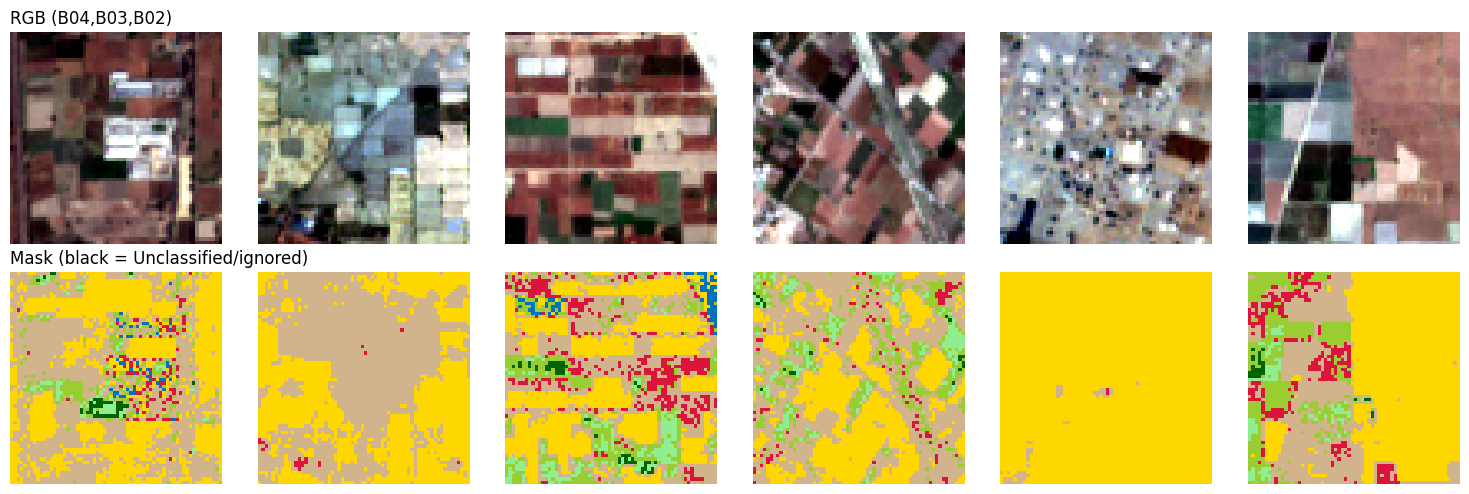

{
 "clean_pairs": {
  "test": 32079,
  "train": 149600,
  "validation": 32079
 },
 "image_sizes": {
  "64x64": 213758
 },
 "constant_image_size": true,
 "leakage_checks": {
  "img_md5_in_multiple_splits": 0,
  "img_md5_duplicated_within_one_split": 0,
  "mask_md5_in_multiple_splits": 0,
  "mask_md5_duplicated_within_one_split": 0,
  "image_filename_stems_in_multiple_splits": 0
 }
}

PART 1 COMPLETE. Compare the counts above with the published description (~213,761 samples); report any discrepancy in your paper.


In [14]:
PAL_RGB = np.array([(0,112,192),(0,100,0),(220,20,60),(154,205,50),(210,180,140),(255,215,0),(144,238,144)], np.uint8)
def colour_src(src):
    o = np.zeros(src.shape + (3,), np.uint8)
    for k in range(1, 8): o[src == k] = PAL_RGB[k-1]
    return o
sm = tr.sample(6, random_state=SEED); fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for j, (_, r) in enumerate(sm.iterrows()):
    ax[0, j].imshow(read_image(r.image_path)); ax[1, j].imshow(colour_src(decode_mask(read_mask_raw(r.mask_path), MASK_ENC))); ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title("RGB (B04,B03,B02)", loc="left"); ax[1, 0].set_title("Mask (black = Unclassified/ignored)", loc="left"); plt.tight_layout()
fig.savefig(f"{ROOT}/dataset_analysis/sample_pairs.png", dpi=200); plt.show()

summary = {"dataset": "Sen-2 LULC", "doi_data": DATASET_DOI, "doi_article": "10.1016/j.dib.2023.109724", "version_requested": DATASET_VERSION,
           "source_used": DATA_SOURCE, "download_date": RUN_STARTED, "mendeley_api_metadata_keys": sorted(DATASET_META.keys()) if DATASET_META else None,
           "pairs_found": {k: v for k, v in unmatched.items()}, "clean_pairs": good.groupby("split").size().to_dict(), "corrupt_pairs": int(len(bad)),
           "image_sizes": {f"{h}x{w}": int(c) for (h, w), c in good.groupby(["img_h", "img_w"]).size().items()}, "constant_image_size": bool(CONST_SIZE),
           "mask_encoding": MASK_ENC, "leakage_checks": leak, "geographic_independence": "NOT verifiable from patch files without coordinates; do not claim it",
           "input_channels": 3, "band_mode": "RGB", "ignored_source_label": 0, "mask_value_note": "model ids 0..6 = source 1..7"}
json.dump(summary, open(f"{ROOT}/dataset_analysis/dataset_summary.json", "w"), indent=2, default=str)
json.dump({"api_log": api_log[-10:], "official_files": OFFICIAL_FILES, "listing_error": LISTING_ERROR, "download_ok": DOWNLOAD_OK, "data_source": DATA_SOURCE,
           "started": RUN_STARTED}, open(f"{OFFICIAL_DIR}/download_report.json", "w"), indent=2, default=str)
if not os.path.exists(f"{OFFICIAL_DIR}/download_manifest.csv"): pd.DataFrame(DL_RECORDS).to_csv(f"{OFFICIAL_DIR}/download_manifest.csv", index=False)
print(json.dumps({k: summary[k] for k in ("clean_pairs", "image_sizes", "constant_image_size", "leakage_checks")}, indent=1))
print("\nPART 1 COMPLETE. Compare the counts above with the published description (~213,761 samples); report any discrepancy in your paper.")

# PART 2 — Model library, genuine DDP training, evaluation

## 12. Central experiment configuration

Everything that defines an experiment lives in `CFG`. **Starting settings, not tuned optima.** `CFG` is set to **`sam2_semantic` + `hiera_bplus`** (official SAM 2.1 Hiera-B+ image encoder + semantic head; 64x64 tiles are upsampled to 256 inside the model and logits are returned at 64x64). Other encoder sizes: `hiera_t`, `hiera_s` (download the matching checkpoint). SAM-specific keys: `sam_ckpt`, `sam_input_size`, `enc_lr_mult` (encoder LR = lr x this), `freeze_encoder`. Unimplemented Part-4 models raise `NotImplementedError` (no silent substitution).

Option menus — **loss:** `ce, wce, dice, ce_dice, focal, focal_dice` · **optimizer:** `adamw, adam, sgd` · **scheduler:** `cosine, plateau, onecycle, constant, warmup_cosine` ·
**class_weighting:** `none, inverse, median, effective, custom` (use with `loss='wce'` or `ce_dice`) · **augmentation:** `none, light, moderate, strong` · **normalization:** `train, imagenet, unit`.
Lovasz-Softmax is not implemented (stated rather than faked).

In [8]:
CFG = dict(
    model="sam2_semantic", encoder="hiera_bplus", pretrained=True,      # official SAM 2.1 Hiera-B+ encoder weights; False = random init
    segformer_checkpoint="nvidia/mit-b0",                               # unused here (kept for helper compatibility)
    sam_ckpt=SAM_CKPT, sam_input_size=128,                              # SAM 2.1 checkpoint (downloaded in Section 2.1); tiles upsampled 64->256 inside the model
    enc_lr_mult=0.1, freeze_encoder=False,                              # encoder LR = lr*0.1; freeze_encoder=True for the frozen-encoder ablation
    input_channels=3, num_classes=7, input_size=None,                   # None = native resolution (reflect-padded to /32 inside the model, cropped back)
    epochs=150, patience=30, monitor="val_miou", seed=42,
    optimizer="adamw", lr=2e-4, weight_decay=0.01, min_lr=1e-6,
    scheduler="warmup_cosine", warmup_epochs=5, plateau_patience=10,
    loss="ce_dice", focal_gamma=2.0, class_weighting="none", custom_class_weights=None,
    augmentation="moderate", normalization="imagenet",   # SAM 2 expects ImageNet mean/std
   
    batch_size=16, eval_batch_size=32, grad_accum=2, grad_clip=1.0,    # batch_size is PER GPU; effective = batch x GPUs x accum
    amp=True, num_workers=2, prefetch=2, sync_bn=False, find_unused_parameters=True, cudnn_benchmark=True,
    time_limit_hours=9.0,                                               # graceful stop before Kaggle's 12 h limit; resume from latest.pt
    resume=None, max_train_samples=None, max_eval_samples=None,        # sub-sampling ONLY for smoke tests
    nproc=2,                                                            # processes = GPUs. 1 => single-GPU debugging fallback
    nccl_p2p_disable=False,                                             # set True if NCCL hangs at start-up on your T4 pair
)
json.dump(CFG, open(f"{ROOT}/reproducibility/default_config.json", "w"), indent=2)
json.dump({str(i): list(c) for i, c in {1:(0,112,192),2:(0,100,0),3:(220,20,60),4:(154,205,50),5:(210,180,140),6:(255,215,0),7:(144,238,144)}.items()},
          open(f"{ROOT}/preprocessing/class_colors.json", "w"), indent=2)
print(json.dumps(CFG, indent=1))

{
 "model": "sam2_semantic",
 "encoder": "hiera_bplus",
 "pretrained": true,
 "segformer_checkpoint": "nvidia/mit-b0",
 "sam_ckpt": "/kaggle/working/lulc_research/code/sam_ckpt/sam2.1_hiera_base_plus.pt",
 "sam_input_size": 128,
 "enc_lr_mult": 0.1,
 "freeze_encoder": false,
 "input_channels": 3,
 "num_classes": 7,
 "input_size": null,
 "epochs": 150,
 "patience": 30,
 "monitor": "val_miou",
 "seed": 42,
 "optimizer": "adamw",
 "lr": 0.0002,
 "weight_decay": 0.01,
 "min_lr": 1e-06,
 "scheduler": "warmup_cosine",
 "warmup_epochs": 5,
 "plateau_patience": 10,
 "loss": "ce_dice",
 "focal_gamma": 2.0,
 "class_weighting": "none",
 "custom_class_weights": null,
 "augmentation": "moderate",
 "normalization": "imagenet",
 "batch_size": 16,
 "eval_batch_size": 32,
 "grad_accum": 2,
 "grad_clip": 1.0,
 "amp": true,
 "num_workers": 2,
 "prefetch": 2,
 "sync_bn": false,
 "find_unused_parameters": true,
 "cudnn_benchmark": true,
 "time_limit_hours": 9.0,
 "resume": null,
 "max_train_samples": null,

## 13. Companion modules (written to `/kaggle/working/lulc_research/code/`)
`common.py`: dataset/augmentation, model registry, losses, confusion-matrix metrics, plots · `train.py`: DDP trainer/evaluator · `smoke_test.py`.

In [16]:
%%writefile /kaggle/working/lulc_research/code/common.py
"""common.py -- dataset, models, losses, metrics, plotting for the Sen-2 LULC benchmark (Part 2)."""
import os, sys, json, time, math, random, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from io_utils import (NUM_CLASSES, IGNORE_INDEX, CLASS_NAMES_SRC, MODEL_CLASS_NAMES, LUT_SRC2MODEL,
                      SRC_FROM_MODEL, read_image, read_mask_raw, decode_mask)

ROOT = os.environ.get("LULC_ROOT", "/kaggle/working/lulc_research")
# One fixed palette used in EVERY figure (source id -> RGB). Saved to preprocessing/class_colors.json by Part 2.
CLASS_COLORS_SRC = {1: (0, 112, 192), 2: (0, 100, 0), 3: (220, 20, 60), 4: (154, 205, 50),
                    5: (210, 180, 140), 6: (255, 215, 0), 7: (144, 238, 144)}
MODEL_COLORS = np.array([CLASS_COLORS_SRC[i] for i in range(1, 8)], dtype=np.uint8)
IGNORE_COLOR = (0, 0, 0)


def load_json(p):
    with open(p) as f:
        return json.load(f)


def save_json(obj, p):
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=str)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def colorize(mask_model):
    """model-id mask (255=ignore) -> HxWx3 uint8 using the shared palette."""
    out = np.zeros(mask_model.shape + (3,), np.uint8)
    out[:] = IGNORE_COLOR
    for k in range(NUM_CLASSES):
        out[mask_model == k] = MODEL_COLORS[k]
    return out


# ----------------------------------------------------------------------------- dataset
AUG_LEVELS = {
    "none":     dict(flip=False, rot=False, bc=0.0, gain=0.0, noise=0.0, blur=0.0),
    "light":    dict(flip=True,  rot=False, bc=0.0, gain=0.0, noise=0.0, blur=0.0),
    "moderate": dict(flip=True,  rot=True,  bc=0.10, gain=0.0, noise=0.0, blur=0.0),
    "strong":   dict(flip=True,  rot=True,  bc=0.20, gain=0.05, noise=0.01, blur=0.2),
}


class LULCDataset(Dataset):
    """Reads (image, mask) pairs from a manifest CSV (columns: id,image_path,mask_path,split).
    Image: RGB scaled to [0,1] by image_encoding.scale_max, then normalised.  Mask: source ids -> model ids (255 ignore).
    Geometric augmentation is applied identically to image and mask; masks are only ever resized with nearest-neighbour."""

    def __init__(self, manifest_csv, cfg, train=False, max_samples=None):
        self.df = pd.read_csv(manifest_csv)
        if max_samples:
            self.df = self.df.sample(n=min(max_samples, len(self.df)), random_state=cfg["seed"]).sort_index().reset_index(drop=True)
        self.ip = self.df["image_path"].tolist(); self.mp = self.df["mask_path"].tolist()
        pre = f"{ROOT}/preprocessing"
        self.enc = load_json(f"{pre}/mask_encoding.json")
        self.scale = float(load_json(f"{pre}/image_encoding.json")["scale_max"])
        nm = cfg["normalization"]
        stats = load_json(f"{ROOT}/preprocessing/normalization_stats.json")
        if nm == "train":
            self.mean, self.std = np.array(stats["train_mean"], np.float32), np.array(stats["train_std"], np.float32)
        elif nm == "imagenet":
            self.mean, self.std = np.array(stats["imagenet_mean"], np.float32), np.array(stats["imagenet_std"], np.float32)
        elif nm == "unit":
            self.mean, self.std = np.zeros(3, np.float32), np.ones(3, np.float32)
        else:
            raise ValueError(nm)
        self.train = train
        self.aug = AUG_LEVELS[cfg["augmentation"]] if train else AUG_LEVELS["none"]
        self.input_size = cfg.get("input_size")  # None = native resolution

    def __len__(self):
        return len(self.ip)

    def _resize(self, img, msk):
        import cv2
        s = self.input_size
        if s and (img.shape[0] != s or img.shape[1] != s):
            img = cv2.resize(img, (s, s), interpolation=cv2.INTER_LINEAR)
            msk = cv2.resize(msk, (s, s), interpolation=cv2.INTER_NEAREST)   # nearest: never creates new class ids
        return img, msk

    def __getitem__(self, i):
        img = read_image(self.ip[i]).astype(np.float32) / self.scale
        msk = LUT_SRC2MODEL[decode_mask(read_mask_raw(self.mp[i]), self.enc)]
        if img.shape[:2] != msk.shape[:2]:
            raise ValueError(f"image/mask shape mismatch: {self.ip[i]} {img.shape} vs {msk.shape}")
        img, msk = self._resize(img, msk)
        a = self.aug
        if self.train:
            if a["flip"]:
                if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
                if random.random() < 0.5: img, msk = img[::-1], msk[::-1]
            if a["rot"]:
                k = random.choice([0, 1, 2, 3] if img.shape[0] == img.shape[1] else [0, 2])
                if k: img, msk = np.rot90(img, k), np.rot90(msk, k)
            if a["bc"] > 0 and random.random() < 0.5:
                c = 1 + random.uniform(-a["bc"], a["bc"]); b = random.uniform(-a["bc"], a["bc"]) * 0.5
                img = (img - 0.5) * c + 0.5 + b
            if a["gain"] > 0 and random.random() < 0.5:
                img = img * (1 + np.random.uniform(-a["gain"], a["gain"], size=(1, 1, 3))).astype(np.float32)
            if a["blur"] > 0 and random.random() < a["blur"]:
                import cv2
                img = cv2.GaussianBlur(np.ascontiguousarray(img), (3, 3), 0)
            if a["noise"] > 0:
                img = img + np.random.normal(0, a["noise"], img.shape).astype(np.float32)
            img = np.clip(img, 0.0, 1.0)
        img = (img - self.mean) / self.std
        x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1), dtype=np.float32))
        y = torch.from_numpy(np.ascontiguousarray(msk).astype(np.int64))
        return x, y, i


class ShardSampler(torch.utils.data.Sampler):
    """Evaluation sampler: rank r takes indices r, r+W, r+2W, ... with NO padding/duplication
    (DistributedSampler pads with repeats, which would double-count samples in the confusion matrix)."""
    def __init__(self, n, rank, world):
        self.idx = list(range(rank, n, world))
    def __iter__(self):
        return iter(self.idx)
    def __len__(self):
        return len(self.idx)


# ----------------------------------------------------------------------------- models
class SegWrapper(nn.Module):
    """Uniform interface: [B,3,H,W] -> [B,7,H,W]. Reflect-pads to a multiple of `multiple`, crops back, and
    bilinearly resizes logits (differentiable) if the net outputs a lower resolution."""
    def __init__(self, net, kind, multiple=32):
        super().__init__(); self.net, self.kind, self.m = net, kind, multiple

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % self.m, (-W) % self.m
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="reflect")
        out = self.net(pixel_values=x) if self.kind == "segformer" else self.net(x)
        out = out.logits if hasattr(out, "logits") else out
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out[..., :H, :W]


def _smp(arch, cfg, pretrained):
    import segmentation_models_pytorch as smp
    cls = {"unet": smp.Unet, "unetplusplus": smp.UnetPlusPlus, "deeplabv3plus": smp.DeepLabV3Plus}[arch]
    w = "imagenet" if pretrained else None
    net = cls(encoder_name=cfg["encoder"], encoder_weights=w, in_channels=3, classes=NUM_CLASSES)
    expected = {"unet": "Unet", "unetplusplus": "UnetPlusPlus", "deeplabv3plus": "DeepLabV3Plus"}[arch]
    assert type(net).__name__ == expected, f"expected {expected}, got {type(net).__name__}"
    return net


def build_model(cfg, pretrained=None):
    """Registry. Heavy imports happen only for the selected model. Raises (never substitutes) for unimplemented ones."""
    name = cfg["model"]
    pre = cfg["pretrained"] if pretrained is None else pretrained
    meta = {"model": name, "pretrained_requested": bool(pre)}
    if name in ("unet", "unetplusplus", "deeplabv3plus"):
        net = _smp(name, cfg, pre)
        meta["source"] = "segmentation_models_pytorch " + __import__("segmentation_models_pytorch").__version__
        meta["pretrained_provenance"] = f"smp encoder weights 'imagenet' for {cfg['encoder']}" if pre else "random init"
        if name == "deeplabv3plus":
            mods = [n.lower() for n, _ in net.named_modules()]
            meta["has_aspp"] = any("aspp" in m for m in mods)
            assert meta["has_aspp"], "DeepLabV3+ decoder without ASPP?"
        model = SegWrapper(net, "smp", 32)
    elif name == "segformer":
        from transformers import SegformerForSemanticSegmentation, SegformerConfig
        id2label = {i: n for i, n in enumerate(MODEL_CLASS_NAMES)}
        if pre:
            net = SegformerForSemanticSegmentation.from_pretrained(
                cfg["segformer_checkpoint"], num_labels=NUM_CLASSES, id2label=id2label,
                label2id={v: k for k, v in id2label.items()}, ignore_mismatched_sizes=True)
            meta["pretrained_provenance"] = f"HF hub '{cfg['segformer_checkpoint']}' (encoder; classifier re-initialised for 7 classes)"
        else:
            c = SegformerConfig.from_pretrained(cfg["segformer_checkpoint"], num_labels=NUM_CLASSES)
            net = SegformerForSemanticSegmentation(c); meta["pretrained_provenance"] = "random init"
        import transformers; meta["source"] = "transformers " + transformers.__version__
        model = SegWrapper(net, "segformer", 32)
    elif name == "sam2_semantic":
        # Official SAM 2.1 Hiera image encoder (facebookresearch/sam2) + light semantic head (sam_models.py)
        from sam_models import build_sam2_semantic
        net, extra = build_sam2_semantic(cfg, pre)
        meta.update(extra)
        model = SegWrapper(net, "sam2", 1)     # multiple=1: no padding; the net resizes internally and returns native-size logits
    elif name in ("rs3mamba", "samba", "sam_rs", "sasam"):
        raise NotImplementedError(f"'{name}' is implemented in Part 4 (requires inspecting the official repository and "
                                  f"verifying mamba_ssm/CUDA compatibility). It is deliberately NOT replaced by another model.")
    else:
        raise ValueError(f"unknown model '{name}'")
    meta["params_total"] = sum(p.numel() for p in model.parameters())
    meta["params_trainable"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, meta


# ----------------------------------------------------------------------------- losses
class SegLoss(nn.Module):
    """ce | wce | dice | ce_dice | focal | focal_dice.   'wce' = CE with class weights.
    Dice: soft dice computed over the batch, averaged over classes PRESENT in the batch ground truth; ignore pixels excluded.
    Lovasz-Softmax is intentionally not offered (not implemented here)."""
    def __init__(self, name, weights=None, gamma=2.0):
        super().__init__()
        self.name, self.gamma = name, gamma
        self.register_buffer("w", None if weights is None else torch.as_tensor(weights, dtype=torch.float32))
        assert name in ("ce", "wce", "dice", "ce_dice", "focal", "focal_dice"), name
        if name == "wce": assert weights is not None, "wce needs class weights"

    def dice(self, logits, y):
        valid = (y != IGNORE_INDEX)
        t = y.clone(); t[~valid] = 0
        p = logits.softmax(1) * valid.unsqueeze(1)
        oh = F.one_hot(t, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
        inter = (p * oh).sum((0, 2, 3)); card = (p + oh).sum((0, 2, 3)); present = oh.sum((0, 2, 3)) > 0
        d = 1 - (2 * inter + 1e-6) / (card + 1e-6)
        return d[present].mean() if present.any() else logits.sum() * 0

    def focal(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX, reduction="none")
        valid = (y != IGNORE_INDEX)
        pt = torch.exp(-F.cross_entropy(logits, y, ignore_index=IGNORE_INDEX, reduction="none"))
        f = ((1 - pt) ** self.gamma) * ce
        return f[valid].sum() / valid.sum().clamp(min=1)

    def forward(self, logits, y):
        logits = logits.float(); n = self.name
        if n in ("ce", "wce"): return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX)
        if n == "dice": return self.dice(logits, y)
        if n == "ce_dice": return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX) + self.dice(logits, y)
        if n == "focal": return self.focal(logits, y)
        return self.focal(logits, y) + self.dice(logits, y)


def class_weights(mode, stats_json, custom=None, beta=0.9999):
    """Weights in MODEL class order (mean-normalised to 1). Treated as an experimental factor, not a default."""
    if mode in (None, "none"): return None
    if mode == "custom": return np.array(custom, np.float32)
    px = np.array(load_json(stats_json)["train_pixels_model_order"], np.float64)
    if mode == "inverse": w = 1.0 / px
    elif mode == "median": f = px / px.sum(); w = np.median(f) / f
    elif mode == "effective": w = (1 - beta) / (1 - beta ** px)
    else: raise ValueError(mode)
    return (w / w.mean()).astype(np.float32)


# ----------------------------------------------------------------------------- metrics (global confusion matrix)
def confusion_from(pred, target):
    """rows = ground truth, cols = prediction; ignore pixels dropped."""
    v = target != IGNORE_INDEX
    idx = target[v] * NUM_CLASSES + pred[v]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def per_image_stats(pred, target):
    """Per-image OA / mIoU / macro-F1 from per-image confusion matrices (classes with GT+pred pixels==0 are skipped)."""
    B = pred.shape[0]; C = NUM_CLASSES
    v = target != IGNORE_INDEX
    off = torch.arange(B, device=pred.device).view(B, 1, 1) * C * C
    idx = (off + target * C + pred)[v]
    cm = torch.bincount(idx, minlength=B * C * C).reshape(B, C, C).double()
    tp = torch.diagonal(cm, dim1=1, dim2=2); gt = cm.sum(2); pr = cm.sum(1); un = gt + pr - tp
    iou = torch.where(un > 0, tp / un.clamp(min=1), torch.full_like(tp, float("nan")))
    f1d = gt + pr
    f1 = torch.where(f1d > 0, 2 * tp / f1d.clamp(min=1), torch.full_like(tp, float("nan")))
    tot = cm.sum((1, 2))
    acc = torch.where(tot > 0, tp.sum(1) / tot.clamp(min=1), torch.full_like(tot, float("nan")))
    return (torch.nanmean(iou, 1).cpu().numpy(), torch.nanmean(f1, 1).cpu().numpy(),
            acc.cpu().numpy(), tot.cpu().numpy())


def metrics_from_cm(cm):
    """All metrics from the *aggregate* confusion matrix. Conventions: a class's IoU/F1 is NaN if it has neither GT nor
    predicted pixels; precision NaN if never predicted; recall NaN if absent from GT. Macro means use nanmean over
    classes that are defined (i.e. averaged over the full dataset, never over per-batch values)."""
    cm = np.asarray(cm, np.float64)
    tp = np.diag(cm); gt = cm.sum(1); pr = cm.sum(0); un = gt + pr - tp; tot = cm.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(un > 0, tp / un, np.nan)
        prec = np.where(pr > 0, tp / pr, np.nan)
        rec = np.where(gt > 0, tp / gt, np.nan)
        f1 = np.where(gt + pr > 0, 2 * tp / (gt + pr), np.nan)
        oa = tp.sum() / tot if tot > 0 else np.nan
        pe = (gt * pr).sum() / tot ** 2 if tot > 0 else np.nan
        kappa = (oa - pe) / (1 - pe) if tot > 0 and pe < 1 else np.nan
        fw = np.nansum((gt / tot) * iou) if tot > 0 else np.nan
    g = dict(oa=oa, miou=np.nanmean(iou), macro_f1=np.nanmean(f1), macro_precision=np.nanmean(prec),
             macro_recall=np.nanmean(rec), fw_iou=fw, kappa=kappa, valid_pixels=int(tot))
    pc = pd.DataFrame({"class_id": np.arange(1, 8), "class_name": MODEL_CLASS_NAMES, "support_pixels": gt.astype(np.int64),
                       "predicted_pixels": pr.astype(np.int64), "iou": iou, "f1_dice": f1, "precision": prec, "recall": rec})
    return g, pc


# ----------------------------------------------------------------------------- plotting
def _save(fig, base, dpi=300):
    fig.savefig(base + ".png", dpi=dpi, bbox_inches="tight")
    fig.savefig(base + ".eps", bbox_inches="tight")   # EPS has no transparency; figures use opaque backgrounds
    import matplotlib.pyplot as plt; plt.close(fig)


def history_figures(hist, outdir):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    for key, ttl, ylab in [("loss", "Loss", "Loss"), ("miou", "Mean IoU", "mIoU"), ("macro_f1", "Macro F1 (Dice)", "F1")]:
        fig, ax = plt.subplots(figsize=(5, 3.4))
        ax.plot(hist["epoch"], hist[f"train_{key}"], label="Train"); ax.plot(hist["epoch"], hist[f"val_{key}"], label="Validation")
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylab); ax.set_title(ttl); ax.legend(); ax.grid(alpha=.3)
        _save(fig, f"{outdir}/curve_{key}")
    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.plot(hist["epoch"], hist["lr"]); ax.set_yscale("log")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate"); ax.set_title("Learning-rate schedule"); ax.grid(alpha=.3)
    _save(fig, f"{outdir}/curve_lr")


def eval_figures(cm, pc, outdir, prefix):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    cm = np.asarray(cm, np.float64)
    for norm in (False, True):
        m = cm / np.maximum(cm.sum(1, keepdims=True), 1) if norm else cm
        fig, ax = plt.subplots(figsize=(6.2, 5.4)); im = ax.imshow(m, cmap="Blues")
        ax.set_xticks(range(7)); ax.set_yticks(range(7))
        ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(MODEL_CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Reference"); ax.set_title(f"{prefix} confusion matrix" + (" (row-normalised)" if norm else ""))
        for i in range(7):
            for j in range(7):
                v = m[i, j]; txt = f"{v:.2f}" if norm else (f"{v:.2e}" if v >= 1e5 else f"{int(v)}")
                ax.text(j, i, txt, ha="center", va="center", fontsize=6, color="white" if v > m.max() * .6 else "black")
        fig.colorbar(im, ax=ax, fraction=.046); _save(fig, f"{outdir}/{prefix}_confusion_{'normalized' if norm else 'raw'}")
    cols = [tuple(c / 255 for c in CLASS_COLORS_SRC[i]) for i in range(1, 8)]
    for key, ttl in [("iou", "Per-class IoU"), ("f1_dice", "Per-class F1 / Dice")]:
        fig, ax = plt.subplots(figsize=(6, 3.6)); ax.bar(MODEL_CLASS_NAMES, pc[key].fillna(0), color=cols, edgecolor="k")
        ax.set_ylim(0, 1); ax.set_ylabel(key.upper()); ax.set_title(f"{prefix}: {ttl}"); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        _save(fig, f"{outdir}/{prefix}_per_class_{key}")
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); x = np.arange(7)
    ax.bar(x - .2, pc["precision"].fillna(0), .4, label="Precision"); ax.bar(x + .2, pc["recall"].fillna(0), .4, label="Recall")
    ax.set_xticks(x); ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_ylim(0, 1); ax.legend(); ax.set_title(f"{prefix}: precision / recall")
    _save(fig, f"{outdir}/{prefix}_per_class_precision_recall")


def save_eval_outputs(prefix, cm, loss, per_img_df, meta, outdir, fig_dir):
    """Writes {prefix}_metrics.csv, _per_class_metrics.csv, _confusion_matrix.csv, _confusion_matrix_normalized.csv,
    _per_image_results.csv and figures. prefix is 'validation' or 'test'."""
    cm = np.asarray(cm); g, pc = metrics_from_cm(cm)
    row = {**meta, "split": prefix, "loss": loss, **g}
    pd.DataFrame([row]).to_csv(f"{outdir}/{prefix}_metrics.csv", index=False)
    pc.to_csv(f"{outdir}/{prefix}_per_class_metrics.csv", index=False)
    lab = [f"{i}:{n}" for i, n in zip(range(1, 8), MODEL_CLASS_NAMES)]
    pd.DataFrame(cm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix.csv")
    nm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    pd.DataFrame(nm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix_normalized.csv")
    if per_img_df is not None:
        per_img_df.to_csv(f"{outdir}/{prefix}_per_image_results.csv", index=False)
    eval_figures(cm, pc, fig_dir, prefix)
    return g, pc


def env_info():
    info = {"python": platform.python_version(), "platform": platform.platform(), "torch": torch.__version__,
            "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(), "n_gpus": torch.cuda.device_count(),
            "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}
    for m in ("segmentation_models_pytorch", "transformers", "timm", "numpy", "pandas", "cv2", "rasterio"):
        try: info[m] = __import__(m).__version__
        except Exception: info[m] = None
    return info

Overwriting /kaggle/working/lulc_research/code/common.py


In [17]:
%%writefile /kaggle/working/lulc_research/code/train.py
"""train.py -- DDP training / evaluation for Sen-2 LULC semantic segmentation.
Launch (2 GPUs):  torchrun --standalone --nproc_per_node=2 train.py --config <exp>/config.json --mode train
Single-GPU / CPU debugging fallback:  python train.py --config <exp>/config.json --mode train
Modes: train (train + validation, uses VAL only) | test (evaluates best checkpoint on the held-out TEST split)."""
import os, sys, json, time, math, argparse, subprocess, contextlib, datetime
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.distributed as dist
from torch.utils.data import DataLoader
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json, save_json


def setup_dist():
    ddp = "RANK" in os.environ and "WORLD_SIZE" in os.environ and int(os.environ["WORLD_SIZE"]) > 1
    if torch.cuda.is_available():
        local = int(os.environ.get("LOCAL_RANK", 0)); torch.cuda.set_device(local); dev = torch.device("cuda", local)
    else:
        local = 0; dev = torch.device("cpu")
    if ddp:
        dist.init_process_group("nccl" if dev.type == "cuda" else "gloo", timeout=datetime.timedelta(minutes=30))
    rank = dist.get_rank() if ddp else 0; world = dist.get_world_size() if ddp else 1
    return ddp, rank, world, local, dev


def allreduce(t, ddp):
    if ddp: dist.all_reduce(t, op=dist.ReduceOp.SUM)
    return t


def gather_obj(obj, ddp, world):
    if not ddp: return [obj]
    out = [None] * world; dist.all_gather_object(out, obj); return out


def nvidia_smi_snapshot():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=index,name,utilization.gpu,memory.used,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True, timeout=20)
        return r.stdout.strip().splitlines()
    except Exception as e:
        return [f"nvidia-smi failed: {e!r}"]


def make_scheduler(cfg, opt, steps_per_epoch):
    s, E = cfg["scheduler"], cfg["epochs"]
    if s == "cosine": return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E, eta_min=cfg["min_lr"]), "epoch"
    if s == "plateau": return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=cfg["plateau_patience"]), "plateau"
    if s == "onecycle": return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=E * steps_per_epoch), "step"
    if s == "constant": return torch.optim.lr_scheduler.LambdaLR(opt, lambda e: 1.0), "epoch"
    if s == "warmup_cosine":
        W = cfg["warmup_epochs"]; floor = cfg["min_lr"] / cfg["lr"]
        f = lambda e: (e + 1) / W if e < W else max(floor, 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, E - W))))
        return torch.optim.lr_scheduler.LambdaLR(opt, f), "epoch"
    raise ValueError(s)


@torch.no_grad()
def evaluate(core, loader, criterion, dev, amp, ddp, world, per_image=False):
    """core = UNWRAPPED model (a DDP forward would broadcast buffers = a collective that deadlocks with uneven shards)."""
    core.eval(); N = C.NUM_CLASSES
    cm = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev); recs = []
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for x, y, idx in loader:
        x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
            logits = core(x)
        loss = criterion(logits, y); pred = logits.argmax(1)
        ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
        cm += C.confusion_from(pred, y)
        if per_image:
            mi, f1, acc, vp = C.per_image_stats(pred, y)
            recs.append(pd.DataFrame({"ds_index": idx.numpy(), "iou": mi, "f1": f1, "accuracy": acc, "valid_pixels": vp}))
    if dev.type == "cuda": torch.cuda.synchronize()
    wall = time.time() - t0
    allreduce(cm, ddp); allreduce(ls, ddp)
    walls = gather_obj(wall, ddp, world)
    df = None
    if per_image:
        mine = pd.concat(recs) if recs else pd.DataFrame(columns=["ds_index", "iou", "f1", "accuracy", "valid_pixels"])
        parts = gather_obj(mine, ddp, world); df = pd.concat(parts).sort_values("ds_index").reset_index(drop=True)
    return cm.cpu().numpy(), float(ls[0] / ls[1]), int(ls[1].item()), max(walls), df


def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--mode", default="train", choices=["train", "test"])
    args = ap.parse_args(); cfg = load_json(args.config)
    ddp, rank, world, local, dev = setup_dist(); is0 = rank == 0
    amp = bool(cfg["amp"]) and dev.type == "cuda"
    C.seed_everything(cfg["seed"])
    torch.backends.cudnn.benchmark = bool(cfg["cudnn_benchmark"])
    exp = cfg["exp_dir"]; os.makedirs(exp, exist_ok=True); fig_dir = f"{exp}/figures"
    log = lambda *a: print(f"[r{rank}]", *a, flush=True) if is0 else None
    if is0 and args.mode == "train": save_json(C.env_info(), f"{exp}/environment.json")
    log(f"mode={args.mode} ddp={ddp} world={world} device={dev} amp={amp} model={cfg['model']}/{cfg.get('encoder')} exp={os.path.basename(exp)}")

    # ---------------- data
    spl = f"{ROOT}/splits"
    def loader_for(split, train):
        ds = C.LULCDataset(f"{spl}/{split}_manifest.csv", cfg, train=train,
                           max_samples=cfg.get("max_train_samples") if train else cfg.get("max_eval_samples"))
        nw = cfg["num_workers"]
        kw = dict(num_workers=nw, pin_memory=dev.type == "cuda", persistent_workers=nw > 0, prefetch_factor=cfg["prefetch"] if nw > 0 else None)
        g = torch.Generator(); g.manual_seed(cfg["seed"] + rank)
        wif = lambda wid: (np.random.seed(cfg["seed"] + rank * 1000 + wid), __import__("random").seed(cfg["seed"] + rank * 1000 + wid))
        if train:
            smp_ = torch.utils.data.distributed.DistributedSampler(ds, world, rank, shuffle=True, seed=cfg["seed"], drop_last=True) if ddp else None
            ld = DataLoader(ds, batch_size=cfg["batch_size"], sampler=smp_, shuffle=smp_ is None, drop_last=True,
                            worker_init_fn=wif, generator=g, **kw)
            return ds, smp_, ld
        return ds, None, DataLoader(ds, batch_size=cfg["eval_batch_size"], sampler=C.ShardSampler(len(ds), rank, world),
                                    worker_init_fn=wif, **kw)

    # ---------------- model / loss
    model, meta = C.build_model(cfg, pretrained=False if args.mode == "test" else None)
    model = model.to(dev)
    if ddp and cfg["sync_bn"] and dev.type == "cuda": model = nn.SyncBatchNorm.convert_sync_batchnorm(model)
    w = C.class_weights(cfg["class_weighting"], f"{ROOT}/dataset_analysis/class_stats.json", cfg.get("custom_class_weights"))
    criterion = C.SegLoss(cfg["loss"], w, cfg["focal_gamma"]).to(dev)
    model_id = f"{cfg['model']}_{cfg.get('encoder', '')}".strip("_")
    base_meta = {"experiment_id": cfg["exp_id"], "model_id": model_id, "seed": cfg["seed"], "params_total": meta["params_total"]}

    # ======================================================================= TEST MODE
    if args.mode == "test":
        ck = torch.load(cfg.get("checkpoint") or f"{exp}/checkpoints/best.pt", map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"]); core = model
        ds, _, ld = loader_for("test", False)
        cm, loss, n, wall, df = evaluate(core, ld, criterion, dev, amp, ddp, world, per_image=True)
        if is0:
            df = df.join(ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "test"); df.insert(2, "model_id", model_id)
            df = df.rename(columns={"id": "image_id"})
            g, pc = C.save_eval_outputs("test", cm, loss, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
            rt = load_json(f"{exp}/runtime.json") if os.path.exists(f"{exp}/runtime.json") else {}
            rt.update({"test_eval_wall_s": wall, "test_images": n, "inference_throughput_img_per_s": n / wall, "inference_world_size": world})
            save_json(rt, f"{exp}/runtime.json")
            print(f"TEST  OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f}", flush=True)
        if ddp: dist.barrier(); dist.destroy_process_group()
        return

    # ======================================================================= TRAIN MODE
    tr_ds, tr_sampler, tr_ld = loader_for("train", True)
    va_ds, _, va_ld = loader_for("validation", False)
    steps_per_epoch = math.ceil(len(tr_ld) / cfg["grad_accum"])
    log(f"train samples={len(tr_ds)} (per-rank batches={len(tr_ld)}), val samples={len(va_ds)}, effective batch="
        f"{cfg['batch_size'] * world * cfg['grad_accum']} (= {cfg['batch_size']} x {world} GPUs x {cfg['grad_accum']} accum), params={meta['params_total']:,}")
    core = model
    if ddp: model = nn.parallel.DistributedDataParallel(core, device_ids=[local] if dev.type == "cuda" else None,
                                                         find_unused_parameters=cfg["find_unused_parameters"])
    params = [p for p in core.parameters() if p.requires_grad]          # used for gradient clipping
    # SAM-style nets expose param_groups() -> lower LR for the pretrained encoder (enc_lr_mult); all other models unchanged
    groups = (core.net.param_groups(cfg["lr"], cfg.get("enc_lr_mult", 0.1), cfg["weight_decay"])
              if hasattr(core.net, "param_groups") else params)
    if cfg["optimizer"] == "adamw": opt = torch.optim.AdamW(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "adam": opt = torch.optim.Adam(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "sgd": opt = torch.optim.SGD(groups, lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"], nesterov=True)
    else: raise ValueError(cfg["optimizer"])
    sched, sched_kind = make_scheduler(cfg, opt, steps_per_epoch)
    try: scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=amp)

    ck_dir = f"{exp}/checkpoints"; os.makedirs(ck_dir, exist_ok=True)
    hist, start, best, best_ep, bad, cum_samples = [], 0, -1e9, -1, 0, 0
    if cfg.get("resume"):
        ck = torch.load(cfg["resume"], map_location=dev, weights_only=False)
        core.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"]); sched.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        hist, start, best, best_ep, bad, cum_samples = ck["history"], ck["epoch"] + 1, ck["best_score"], ck["best_epoch"], ck["bad_epochs"], ck["cum_samples"]
        torch.set_rng_state(ck["rng"]["torch"].cpu()); np.random.set_state(ck["rng"]["numpy"]); __import__("random").setstate(ck["rng"]["python"])
        log(f"RESUMED from {cfg['resume']} -> starting at epoch {start + 1}")

    N = C.NUM_CLASSES; accum = cfg["grad_accum"]; t_start = time.time(); my_samples = 0; smi = None; mon = cfg["monitor"]
    if dev.type == "cuda": torch.cuda.reset_peak_memory_stats()
    stop_flag = torch.zeros(1, device=dev)
    for epoch in range(start, cfg["epochs"]):
        t_ep = time.time(); model.train()
        if tr_sampler is not None: tr_sampler.set_epoch(epoch)       # different shuffle every epoch
        cm_tr = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev)
        opt.zero_grad(set_to_none=True)
        for i, (x, y, _) in enumerate(tr_ld):
            x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
            do_step = ((i + 1) % accum == 0) or (i + 1 == len(tr_ld))
            ctx = model.no_sync() if (ddp and not do_step) else contextlib.nullcontext()
            with ctx:
                with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
                    logits = model(x)
                loss = criterion(logits, y)
                scaler.scale(loss / accum).backward()
            if do_step:
                if cfg["grad_clip"] > 0:
                    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, cfg["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                if sched_kind == "step": sched.step()
            with torch.no_grad():
                cm_tr += C.confusion_from(logits.argmax(1), y); ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
            my_samples += x.size(0)
            if epoch == start and i == min(20, len(tr_ld) - 1) and is0 and dev.type == "cuda":
                smi = nvidia_smi_snapshot(); log("nvidia-smi snapshot during training (all GPUs):\n  " + "\n  ".join(smi))
        allreduce(cm_tr, ddp); allreduce(ls, ddp)
        tr_g, _ = C.metrics_from_cm(cm_tr.cpu().numpy()); tr_loss = float(ls[0] / ls[1]); ep_samples = int(ls[1].item()); cum_samples += ep_samples
        cm_v, v_loss, _, _, _ = evaluate(core, va_ld, criterion, dev, amp, ddp, world)
        v_g, _ = C.metrics_from_cm(cm_v)
        score = {"val_miou": v_g["miou"], "val_f1": v_g["macro_f1"], "val_oa": v_g["oa"], "val_loss": -v_loss}[mon]
        lr_now = opt.param_groups[0]["lr"]
        if sched_kind == "epoch": sched.step()
        elif sched_kind == "plateau": sched.step(v_g["miou"])
        peaks = gather_obj(torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0, ddp, world)
        improved = score > best + 1e-6
        if is0:
            if improved: best, best_ep, bad = score, epoch, 0
            else: bad += 1
            row = dict(epoch=epoch + 1, train_loss=tr_loss, val_loss=v_loss, train_oa=tr_g["oa"], val_oa=v_g["oa"], train_miou=tr_g["miou"],
                       val_miou=v_g["miou"], train_macro_f1=tr_g["macro_f1"], val_macro_f1=v_g["macro_f1"], lr=lr_now,
                       epoch_time_s=time.time() - t_ep, peak_mem_mb_max=max(peaks), peak_mem_mb_per_rank=json.dumps([round(p) for p in peaks]),
                       samples_this_epoch=ep_samples, cum_samples=cum_samples, best_epoch=best_ep + 1, bad_epochs=bad)
            hist.append(row); pd.DataFrame(hist).to_csv(f"{exp}/train_history.csv", index=False)
            state = dict(model=core.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                         best_score=best, best_epoch=best_ep, bad_epochs=bad, cum_samples=cum_samples, history=hist, cfg=cfg, model_meta=meta,
                         label_mapping=load_json(f"{ROOT}/preprocessing/label_mapping.json"),
                         normalization=load_json(f"{ROOT}/preprocessing/normalization_stats.json"),
                         rng=dict(torch=torch.get_rng_state(), numpy=np.random.get_state(), python=__import__("random").getstate()))
            torch.save(state, f"{ck_dir}/latest.pt")
            if improved: torch.save(state, f"{ck_dir}/best.pt")
            bestmark = "*best*" if improved else "bad %d/%d" % (bad, cfg["patience"])
            print(f"Ep {epoch + 1:3d}/{cfg['epochs']} | loss {tr_loss:.4f}/{v_loss:.4f} | OA {tr_g['oa']:.4f}/{v_g['oa']:.4f} | mIoU {tr_g['miou']:.4f}/"
                  f"{v_g['miou']:.4f} | F1(val) {v_g['macro_f1']:.4f} | lr {lr_now:.2e} | {row['epoch_time_s']:.0f}s | peakMB {[round(p) for p in peaks]} "
                  f"| {bestmark}", flush=True)
            stop = bad >= cfg["patience"] or (time.time() - t_start) / 3600 > cfg["time_limit_hours"]
            if stop and bad < cfg["patience"]: print("Wall-clock limit reached: stopping gracefully; resume from latest.pt", flush=True)
            stop_flag.fill_(1.0 if stop else 0.0)
        if ddp: dist.broadcast(stop_flag, src=0)                       # synchronized early stopping
        if stop_flag.item() > 0: break

    train_time = time.time() - t_start
    # ---------------- per-rank participation report (proof that BOTH GPUs did work)
    rep = dict(rank=rank, local_rank=local, world_size=world, pid=os.getpid(), device=str(dev),
               cuda_current_device=torch.cuda.current_device() if dev.type == "cuda" else None,
               gpu_name=torch.cuda.get_device_name(local) if dev.type == "cuda" else "cpu",
               train_samples_processed_by_this_rank=my_samples,
               peak_mem_allocated_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0)
    reps = gather_obj(rep, ddp, world)
    # ---------------- final validation with best checkpoint (VALIDATION only)
    ck = torch.load(f"{ck_dir}/best.pt", map_location=dev, weights_only=False); core.load_state_dict(ck["model"])
    cm, vl, n, wall, df = evaluate(core, va_ld, criterion, dev, amp, ddp, world, per_image=True)
    if is0:
        df = df.join(va_ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "validation"); df.insert(2, "model_id", model_id)
        df = df.rename(columns={"id": "image_id"})
        g, pc = C.save_eval_outputs("validation", cm, vl, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
        C.history_figures(pd.DataFrame(hist), fig_dir)
        flops = None
        try:
            from torch.utils.flop_counter import FlopCounterMode
            core.eval(); x0 = va_ds[0][0].unsqueeze(0).to(dev)
            with torch.no_grad(), FlopCounterMode(display=False) as fc: core(x0)
            flops = fc.get_total_flops()
        except Exception as e: print("FLOP counting unavailable:", repr(e))
        save_json({"ranks": reps, "nvidia_smi_snapshot": smi, "world_size": world}, f"{exp}/rank_report.json")
        save_json({"train_time_s": train_time, "epochs_run": len(hist), "best_epoch": best_ep + 1, "avg_epoch_time_s": float(np.mean([h["epoch_time_s"] for h in hist])) if hist else None,
                   "peak_mem_mb_max": max(r["peak_mem_allocated_mb"] for r in reps), "params_total": meta["params_total"], "params_trainable": meta["params_trainable"],
                   "forward_flops_per_image": flops, "forward_macs_per_image_approx": flops / 2 if flops else None, "val_eval_wall_s": wall,
                   "val_images": n, "val_throughput_img_per_s": n / wall, "world_size": world, "effective_batch": cfg["batch_size"] * world * accum,
                   "samples_per_rank": [r["train_samples_processed_by_this_rank"] for r in reps], "model_meta": meta}, f"{exp}/runtime.json")
        print(f"\nBEST epoch {ck['epoch'] + 1} | VAL OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f} | train {train_time / 60:.1f} min", flush=True)
        print("RANK REPORT:\n" + "\n".join(json.dumps(r) for r in reps), flush=True)
    if ddp: dist.barrier(); dist.destroy_process_group()


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/lulc_research/code/train.py


In [18]:
%%writefile /kaggle/working/lulc_research/code/sam_models.py
"""sam_models.py -- SAM 2.1 (official facebookresearch/sam2 Hiera image encoder + FPN neck) with a light semantic head.
Reference: Ravi et al., 'SAM 2: Segment Anything in Images and Videos', ICLR 2025, arXiv:2408.00714.
SAM's own mask decoder is prompt-based/class-agnostic, so ONLY the pretrained image encoder is used; the semantic head is new."""
import torch, torch.nn as nn, torch.nn.functional as F

SAM2_CFG = {"hiera_t": "configs/sam2.1/sam2.1_hiera_t.yaml",
            "hiera_s": "configs/sam2.1/sam2.1_hiera_s.yaml",
            "hiera_bplus": "configs/sam2.1/sam2.1_hiera_b+.yaml"}


def _cgn(i, o, k):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.GroupNorm(16, o), nn.ReLU(True))


class SamHieraSeg(nn.Module):
    def __init__(self, cfg_yaml, ckpt, num_classes, in_size=256, dec_ch=128, freeze=False):
        super().__init__()
        from sam2.build_sam import build_sam2
        sam = build_sam2(cfg_yaml, ckpt_path=ckpt, device="cpu")      # ckpt=None -> random init
        self.encoder, self.in_size = sam.image_encoder, in_size
        del sam                                                       # drop prompt encoder / mask decoder / memory modules
        with torch.no_grad():
            out = self.encoder(torch.zeros(1, 3, in_size, in_size))
            assert "backbone_fpn" in out, f"unexpected encoder output keys: {list(out.keys())}"
            feats = out["backbone_fpn"]
        self.proj = nn.ModuleList([_cgn(f.shape[1], dec_ch, 1) for f in feats])
        self.fuse = _cgn(dec_ch * len(feats), dec_ch, 3)
        self.cls = nn.Sequential(nn.Dropout2d(0.1), nn.Conv2d(dec_ch, num_classes, 1))
        if freeze:
            for p in self.encoder.parameters(): p.requires_grad_(False)

    def forward(self, x):
        H, W = x.shape[-2:]
        x = F.interpolate(x, size=(self.in_size,) * 2, mode="bilinear", align_corners=False)
        feats = self.encoder(x)["backbone_fpn"]
        sz = feats[0].shape[-2:]                                       # finest level (stride 4)
        y = torch.cat([F.interpolate(p(f), size=sz, mode="bilinear", align_corners=False)
                       for p, f in zip(self.proj, feats)], 1)
        y = self.cls(self.fuse(y))
        return F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)

    def param_groups(self, lr, enc_mult, wd):
        enc = [p for p in self.encoder.parameters() if p.requires_grad]
        dec = [p for n, p in self.named_parameters() if not n.startswith("encoder.") and p.requires_grad]
        g = [dict(params=dec, lr=lr, weight_decay=wd)]
        if enc: g.append(dict(params=enc, lr=lr * enc_mult, weight_decay=wd))
        return g


def build_sam2_semantic(cfg, pretrained):
    ck = cfg["sam_ckpt"] if pretrained else None
    net = SamHieraSeg(SAM2_CFG[cfg["encoder"]], ck, cfg["num_classes"], cfg.get("sam_input_size", 256),
                      freeze=cfg.get("freeze_encoder", False))
    return net, {"source": "facebookresearch/sam2 (SAM 2.1 Hiera image encoder) + custom semantic head",
                 "pretrained_provenance": ck or "random init"}


Overwriting /kaggle/working/lulc_research/code/sam_models.py


In [19]:
%%writefile /kaggle/working/lulc_research/code/smoke_test.py
"""smoke_test.py -- run in a SUBPROCESS (keeps CUDA contexts out of the notebook kernel).
  python smoke_test.py --config cfg.json --stage data
  python smoke_test.py --config cfg.json --stage models --models sam2_semantic"""
import os, sys, json, time, argparse, copy
import numpy as np, pandas as pd, torch
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json

ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--stage", required=True, choices=["data", "models"])
ap.add_argument("--models", nargs="*", default=["sam2_semantic"]); a = ap.parse_args()
cfg = load_json(a.config)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if a.stage == "data":
    for split in ("train", "validation", "test"):
        ds = C.LULCDataset(f"{ROOT}/splits/{split}_manifest.csv", cfg, train=(split == "train"))
        x, y, i = ds[0]
        u = torch.unique(y).tolist()
        assert x.shape[0] == 3 and x.dtype == torch.float32 and y.dtype == torch.int64 and x.shape[-2:] == y.shape, (x.shape, y.shape)
        assert set(u) <= set(range(7)) | {255}, f"invalid class ids in mask: {u}"
        # augmentation must not create new class ids and must keep image/mask aligned in shape
        if split == "train":
            for k in range(30):
                x2, y2, _ = ds[k % len(ds)]; assert x2.shape[-2:] == y2.shape; assert set(torch.unique(y2).tolist()) <= set(range(7)) | {255}
        b = next(iter(torch.utils.data.DataLoader(ds, batch_size=4, num_workers=0)))
        print(f"[{split}] n={len(ds)} sample x={tuple(x.shape)} mask_ids={u} batch={tuple(b[0].shape)} x.mean={x.mean():.3f} x.std={x.std():.3f}")
    print("DATA SMOKE TEST PASSED")
else:
    rows = []
    for name in a.models:
        c = copy.deepcopy(cfg); c["model"] = name
        if name == "segformer": c["encoder"] = c["segformer_checkpoint"].split("/")[-1]
        elif name != cfg["model"] and c["encoder"].startswith("mit"): c["encoder"] = "resnet34"
        r = {"model": name}
        try:
            torch.cuda.reset_peak_memory_stats() if dev.type == "cuda" else None
            model, meta = C.build_model(c); model = model.to(dev).train()
            H = int(cfg.get("input_size") or 256); x = torch.randn(2, 3, H, H, device=dev); y = torch.randint(0, 7, (2, H, H), device=dev); y[:, :8, :8] = 255
            crit = C.SegLoss(c["loss"], None).to(dev); opt = torch.optim.AdamW(model.parameters(), 1e-4)
            with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
                out = model(x)
            assert out.shape == (2, 7, H, H), out.shape
            loss = crit(out, y); loss.backward(); gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            assert torch.isfinite(loss) and torch.isfinite(gn)
            r.update(status="OK", out_shape=str(tuple(out.shape)), loss=float(loss), params_M=meta["params_total"] / 1e6,
                     peak_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else None,
                     pretrained=meta["pretrained_provenance"], class_=type(model.net).__name__, aspp=meta.get("has_aspp"))
        except Exception as e:
            r.update(status="FAIL", error=repr(e)[:300])
        rows.append(r); print(r, flush=True)
        del model; torch.cuda.empty_cache() if dev.type == "cuda" else None
    df = pd.DataFrame(rows); print(df.to_string()); df.to_csv(f"{ROOT}/reproducibility/model_smoke_test.csv", index=False)
    print("MODEL SMOKE TEST:", "PASSED" if (df.status == "OK").all() else "SOME MODELS FAILED (see above)")

Overwriting /kaggle/working/lulc_research/code/smoke_test.py


## 14. Experiment helpers
`new_experiment()` creates a **unique** directory (`model_encoder_seedN_timestamp`) and never overwrites; `launch()` runs a *real* multi-process job with `torchrun`.

In [4]:
import glob, copy
CODE = f"{ROOT}/code"
def new_experiment(overrides=None, tag=""):
    c = copy.deepcopy(CFG); c.update(overrides or {})
    enc = c["segformer_checkpoint"].split("/")[-1] if c["model"] == "segformer" else c["encoder"]
    if c["model"] == "segformer": c["encoder"] = enc
    ts = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    c["exp_id"] = f"{c['model']}_{enc}_seed{c['seed']}{tag}_{ts}"; c["exp_dir"] = f"{ROOT}/experiments/{c['exp_id']}"
    os.makedirs(c["exp_dir"], exist_ok=False); json.dump(c, open(f"{c['exp_dir']}/config.json", "w"), indent=2)
    return c

def launch(c, mode="train"):
    env = dict(os.environ, LULC_ROOT=ROOT, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1")
    if c.get("nccl_p2p_disable"): env["NCCL_P2P_DISABLE"] = "1"
    cmd = (["torchrun", "--standalone", f"--nproc_per_node={c['nproc']}"] if c["nproc"] > 1 else [sys.executable])
    cmd += [f"{CODE}/train.py", "--config", f"{c['exp_dir']}/config.json", "--mode", mode]
    print("$", " ".join(cmd)); t0 = time.time()
    with open(f"{c['exp_dir']}/{mode}_log.txt", "w") as log:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
        for line in p.stdout: print(line, end=""); log.write(line)
        p.wait()
    print(f"\nexit code {p.returncode} | {(time.time()-t0)/60:.1f} min")
    return p.returncode

def check_dual_gpu(c):
    """Fail loudly unless every rank processed data on a distinct GPU."""
    r = json.load(open(f"{c['exp_dir']}/rank_report.json")); df = pd.DataFrame(r["ranks"]); display(df)
    print("nvidia-smi snapshot taken during training:"); print("\n".join(r.get("nvidia_smi_snapshot") or ["(none)"]))
    assert len(df) == c["nproc"], "rank report incomplete"
    if c["nproc"] > 1:
        assert df.cuda_current_device.nunique() == len(df), "ranks did not use distinct GPUs"
        assert (df.train_samples_processed_by_this_rank > 0).all(), "a rank processed no samples"
        print(f"VERIFIED: {len(df)} ranks, distinct GPUs {df.cuda_current_device.tolist()}, samples per rank {df.train_samples_processed_by_this_rank.tolist()}, "
              f"peak MB {df.peak_mem_allocated_mb.round().tolist()}")

## 15. Smoke tests (run in subprocesses; no CUDA context in this kernel)
**(a)** data pipeline — shapes, class ids, augmentation sanity · **(b)** the SAM 2.1 model: init → forward → output `[B,7,H,W]` → loss → backward → optimizer step

In [21]:
smoke_cfg = new_experiment({}, tag="_smokecfg")
for stage, extra in (("data", []), ("models", ["--models", "sam2_semantic"])):
    r = subprocess.run([sys.executable, f"{CODE}/smoke_test.py", "--config", f"{smoke_cfg['exp_dir']}/config.json", "--stage", stage] + extra,
                       capture_output=True, text=True, env=dict(os.environ, LULC_ROOT=ROOT)); print(r.stdout[-3500:]); print(r.stderr[-1500:] if r.returncode else "")
    assert r.returncode == 0, f"{stage} smoke test failed - fix before training"

[train] n=149600 sample x=(3, 64, 64) mask_ids=[0, 1, 2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.735 x.std=1.151
[validation] n=32079 sample x=(3, 64, 64) mask_ids=[0, 1, 2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.025 x.std=1.182
[test] n=32079 sample x=(3, 64, 64) mask_ids=[2, 3, 4, 5, 6] batch=(4, 3, 64, 64) x.mean=0.257 x.std=1.044
DATA SMOKE TEST PASSED


{'model': 'sam2_semantic', 'status': 'OK', 'out_shape': '(2, 7, 256, 256)', 'loss': 2.869694709777832, 'params_M': 69.649415, 'peak_mb': 1451.48291015625, 'pretrained': '/kaggle/working/lulc_research/code/sam_ckpt/sam2.1_hiera_base_plus.pt', 'class_': 'SamHieraSeg', 'aspp': None}
           model status         out_shape      loss   params_M     peak_mb                                                             pretrained       class_  aspp
0  sam2_semantic     OK  (2, 7, 256, 256)  2.869695  69.649415  1451.48291  /kaggle/working/lulc_research/code/sam_ckpt/sam2.1_hiera_base_plus.pt  SamHieraSeg  None
MODEL SMOKE TEST: PASSE

## 16. DDP smoke run (2 epochs, 2 048 training images) + dual-GPU verification + checkpoint-resume test
This exercises `torchrun`, `DistributedSampler.set_epoch`, all-reduced confusion matrices, rank-0 checkpointing and early-stop broadcast. **Inspect the rank table** — it is the evidence that both GPUs worked.

In [22]:
SMOKE = dict(epochs=2, max_train_samples=2048, max_eval_samples=512, patience=30)
c_smoke = new_experiment({**SMOKE}, tag="_ddpsmoke")
assert launch(c_smoke, "train") == 0, "DDP smoke run failed - read the log above (try nccl_p2p_disable=True if it hung at start-up)"
check_dual_gpu(c_smoke)
# resume test: continue the same run to epoch 3 from latest.pt
c_res = new_experiment({**SMOKE, "epochs": 3, "resume": f"{c_smoke['exp_dir']}/checkpoints/latest.pt"}, tag="_resumetest")
assert launch(c_res, "train") == 0
h = pd.read_csv(f"{c_res['exp_dir']}/train_history.csv"); print("history epochs after resume:", h.epoch.tolist()); assert h.epoch.tolist() == [1, 2, 3], "resume did not continue correctly"
print("SMOKE + RESUME OK. (Smoke runs are test artefacts; they are excluded from experiment_summary by tag.)")

$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_ddpsmoke_20261015_071854/config.json --mode train
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=sam2_semantic/hiera_bplus exp=sam2_semantic_hiera_bplus_seed42_ddpsmoke_20261015_071854
[r0] train samples=2048 (per-rank batches=64), val samples=512, effective batch=64 (= 16 x 2 GPUs x 2 accum), params=69,649,415
[rank1]:[W1015 07:19:14.931055149 reducer.cpp:1502] Warning: find_unused_parameters=True was specified in DDP constructor, but did not find any unused parameters in the forward pass. This flag results in an extra traversal of the autograd graph every iteration,  which can adversely affect performance. If your model indeed never has any unused parameters in the forward pass, consider turning this flag off. Note that this warning may be a false positive if your model has flow control causing later 

OSError: [Errno 28] No space left on device

## 17. FULL TRAINING — SAM 2.1 (Hiera-B+) on the official training split
Training uses the **validation** split only (early stopping, LR scheduling, model selection). The run stops gracefully after `CFG['time_limit_hours']` (set to 9 h so that data preparation + testing still fit Kaggle's 12 h session; raise it if your preparation is fast) and can be resumed later with `CFG['resume']=<exp>/checkpoints/latest.pt` (set it via `new_experiment({'resume': ...})`).


In [ ]:
# c_main = new_experiment({}, tag="")          # defaults from CFG: SAM 2.1 Hiera-B+ semantic segmentation, 40 epochs, patience 10, seed 42
# print("Experiment:", c_main["exp_id"])
# rc = launch(c_main, "train")
# assert rc == 0, "training failed - read the log above"
# check_dual_gpu(c_main)

In [ ]:
# EXP_DIR = c_main["exp_dir"]                       # or hard-code e.g. f"{ROOT}/experiments/sam2_semantic_hiera_bplus_seed42_<timestamp>"
# LATEST  = f"{EXP_DIR}/checkpoints/latest.pt"
# assert os.path.exists(LATEST), "no latest.pt to resume from"

# c_main = json.load(open(f"{EXP_DIR}/config.json"))
# c_main["resume"] = LATEST                         # train.py restores the latest checkpoint
# c_main["epochs"] = 40                             # TOTAL target epochs, not "additional" epochs
# json.dump(c_main, open(f"{EXP_DIR}/config.json", "w"), indent=2)   # launch() reads config.json from disk

# rc = launch(c_main, "train")
# if rc == 0: check_dual_gpu(c_main)

In [5]:
# ============================================================
# AUTOMATIC EXPERIMENT DISCOVERY + RESUME TRAINING
# Supports U-Net, SegFormer, and DeepLabV3+
# ============================================================

import os
import json
import torch

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------
ROOT = "/kaggle/working/lulc_research"
EXP_ROOT = os.path.join(ROOT, "experiments")

MODEL = "sam2_semantic"  # "unet", "segformer", "deeplabv3plus"
TARGET_EPOCHS = 150

# ------------------------------------------------------------
# 2. FIND AVAILABLE EXPERIMENTS
# ------------------------------------------------------------
experiments = []

for exp_id in os.listdir(EXP_ROOT):

    # Only select the requested architecture
    if not exp_id.startswith(MODEL + "_"):
        continue

    # Exclude smoke and resume tests
    if any(tag in exp_id for tag in [
        "_ddpsmoke_",
        "_resumetest_",
        "_smokecfg_"
    ]):
        continue

    exp_dir = os.path.join(EXP_ROOT, exp_id)
    latest = os.path.join(exp_dir, "checkpoints", "latest.pt")
    config = os.path.join(exp_dir, "config.json")

    if os.path.isfile(latest) and os.path.isfile(config):
        experiments.append({
            "exp_id": exp_id,
            "exp_dir": exp_dir,
            "latest": latest,
            "config": config,
            "modified": os.path.getmtime(latest)
        })

if not experiments:
    raise FileNotFoundError(
        f"No resumable {MODEL} experiment found in {EXP_ROOT}. "
        "Check whether your Kaggle checkpoints were preserved."
    )

# Most recently saved checkpoint first
experiments.sort(
    key=lambda x: x["modified"],
    reverse=True
)

# ------------------------------------------------------------
# 3. SELECT THE LATEST EXPERIMENT
# ------------------------------------------------------------
selected = experiments[0]

EXP_ID = selected["exp_id"]
EXP_DIR = selected["exp_dir"]
LATEST = selected["latest"]

print("=" * 65)
print("SELECTED EXPERIMENT")
print("=" * 65)
print("Experiment ID :", EXP_ID)
print("Directory     :", EXP_DIR)
print("Checkpoint    :", LATEST)

# ------------------------------------------------------------
# 4. INSPECT SAVED TRAINING STATE
# ------------------------------------------------------------
ck = torch.load(
    LATEST,
    map_location="cpu",
    weights_only=False
)

completed_epoch = int(ck["epoch"]) + 1
next_epoch = completed_epoch + 1

print("\nTRAINING STATUS")
print("Last completed epoch :", completed_epoch)
print("Next epoch           :", next_epoch)
print("Target epochs        :", TARGET_EPOCHS)
print("Best epoch           :", int(ck["best_epoch"]) + 1)
print("Best validation score:", ck["best_score"])

# ------------------------------------------------------------
# 5. LOAD ORIGINAL EXPERIMENT CONFIGURATION
# ------------------------------------------------------------
with open(selected["config"], "r") as f:
    c_main = json.load(f)

# Confirm architecture matches checkpoint selection
assert c_main["model"] == MODEL, (
    f"Model mismatch: expected {MODEL}, "
    f"found {c_main['model']}"
)

# Keep the original training settings.
# Change only checkpoint and target epoch configuration.
c_main["resume"] = LATEST
c_main["epochs"] = TARGET_EPOCHS
c_main["sam_input_size"] = 128
c_main["find_unused_parameters"] = False
c_main["patience"] = 50

# Important: resume within the SAME experiment directory
c_main["exp_id"] = EXP_ID
c_main["exp_dir"] = EXP_DIR

# ------------------------------------------------------------
# 6. CHECK IF TRAINING IS ALREADY COMPLETE
# ------------------------------------------------------------
if completed_epoch >= TARGET_EPOCHS:
    print("\nTraining already reached the target epochs.")
    print("No additional training required.")

else:
    # Save the updated experiment configuration
    with open(selected["config"], "w") as f:
        json.dump(c_main, f, indent=2)

    print("\n" + "=" * 65)
    print(f"RESUMING TRAINING FROM EPOCH {next_epoch}")
    print("=" * 65)

    # Free checkpoint memory before training
    del ck

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # 7. RESUME TRAINING
    # --------------------------------------------------------
    rc = launch(c_main, "train")

    if rc == 0:
        print("\nTraining completed successfully.")
        check_dual_gpu(c_main)
    else:
        raise RuntimeError(
            f"Training failed with exit code {rc}. "
            "Inspect the training log above."
        )

SELECTED EXPERIMENT
Experiment ID : sam2_semantic_hiera_bplus_seed42_20261013_035848
Directory     : /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848
Checkpoint    : /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848/checkpoints/latest.pt

TRAINING STATUS
Last completed epoch : 53
Next epoch           : 54
Target epochs        : 150
Best epoch           : 13
Best validation score: 0.6579047603211988


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

## 18. Held-out TEST evaluation (run once, after model selection is final)

In [14]:
import torch, json, pandas as pd
EXP = "/kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848"
ck = torch.load(f"{EXP}/checkpoints/best.pt", map_location="cpu", weights_only=False)
print("epoch", ck["epoch"] + 1, "best_score", ck["best_score"])
print("cfg in best.pt:", {k: ck["cfg"][k] for k in ("sam_input_size","normalization","augmentation","encoder","loss")})
print("cfg in config.json:", {k: json.load(open(f"{EXP}/config.json"))[k] for k in ("sam_input_size","normalization","augmentation","encoder","loss")})
h = pd.read_csv(f"{EXP}/train_history.csv"); print(h.loc[h.epoch.isin([12,13,14]), ["epoch","val_loss","val_miou","best_epoch"]])

epoch 13 best_score 0.6579047603211988
cfg in best.pt: {'sam_input_size': 256, 'normalization': 'imagenet', 'augmentation': 'moderate', 'encoder': 'hiera_bplus', 'loss': 'ce_dice'}
cfg in config.json: {'sam_input_size': 128, 'normalization': 'imagenet', 'augmentation': 'moderate', 'encoder': 'hiera_bplus', 'loss': 'ce_dice'}
    epoch  val_loss  val_miou  best_epoch
11     12  0.548645  0.642590          12
12     13  0.531685  0.657905          13
13     14  0.525780  0.654526          13


In [8]:
import json, os
ROOT = "/kaggle/working/lulc_research"
EXP_DIR = f"{ROOT}/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848"
c_main = json.load(open(f"{EXP_DIR}/config.json"))
c_main["max_eval_samples"] = None     # evaluate on the full test set
c_main["resume"] = None               # not needed for testing
print(c_main["exp_id"], c_main["model"], c_main["sam_input_size"])

sam2_semantic_hiera_bplus_seed42_20261013_035848 sam2_semantic 128


In [15]:
import json
EXP = "/kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848"
p = f"{EXP}/config.json"
c = json.load(open(p)); c["sam_input_size"] = 256
tmp = p + ".tmp"; json.dump(c, open(tmp, "w"), indent=2); os.replace(tmp, p)

c_main = json.load(open(p)); c_main["max_eval_samples"] = None; c_main["resume"] = None
print(c_main["sam_input_size"])

256


In [16]:
assert os.path.exists(f"{c_main['exp_dir']}/checkpoints/best.pt")
assert launch(c_main, "test") == 0
for f in ("validation_metrics", "test_metrics"): display(pd.read_csv(f"{c_main['exp_dir']}/{f}.csv").T)
display(pd.read_csv(f"{c_main['exp_dir']}/test_per_class_metrics.csv").round(4))

$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261013_035848/config.json --mode test
[r0] mode=test ddp=True world=2 device=cuda:0 amp=True model=sam2_semantic/hiera_bplus exp=sam2_semantic_hiera_bplus_seed42_20261013_035848
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
TEST  OA=0.8903 mIoU=0.6580 F1=0.7847 kappa=0.8370
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)

exit code 0 | 2.2 min


,0
experiment_id,sam2_semantic_hiera_bplus_seed42_20261013_035848
model_id,sam2_semantic_hiera_bplus
seed,42
params_total,69649415
best_epoch,13
n_images,32079
split,validation
loss,1.990501
oa,0.700959
miou,0.317493


,0
experiment_id,sam2_semantic_hiera_bplus_seed42_20261013_035848
model_id,sam2_semantic_hiera_bplus
seed,42
params_total,69649415
best_epoch,13
n_images,32079
split,test
loss,0.529947
oa,0.890329
miou,0.658027


,class_id,class_name,support_pixels,predicted_pixels,iou,f1_dice,precision,recall
0,1,Water Bodies,1433726,1512671,0.4594,0.6296,0.6131,0.6469
1,2,Dense Forest,1616488,1914977,0.4985,0.6654,0.6135,0.7268
2,3,Built up,7406266,7722220,0.6253,0.7695,0.7537,0.7859
3,4,Agriculture land,14164093,14551442,0.6690,0.8017,0.7910,0.8127
4,5,Barren land,36887105,38028366,0.7848,0.8795,0.8663,0.8931
5,6,Fallow land,64370382,61268997,0.9106,0.9532,0.9773,0.9302
6,7,Sparse Forest,5517515,6396902,0.6585,0.7941,0.7395,0.8574


## 19. Training curves & confusion matrices (PNG shown; EPS saved alongside at 300 dpi)

curve_loss


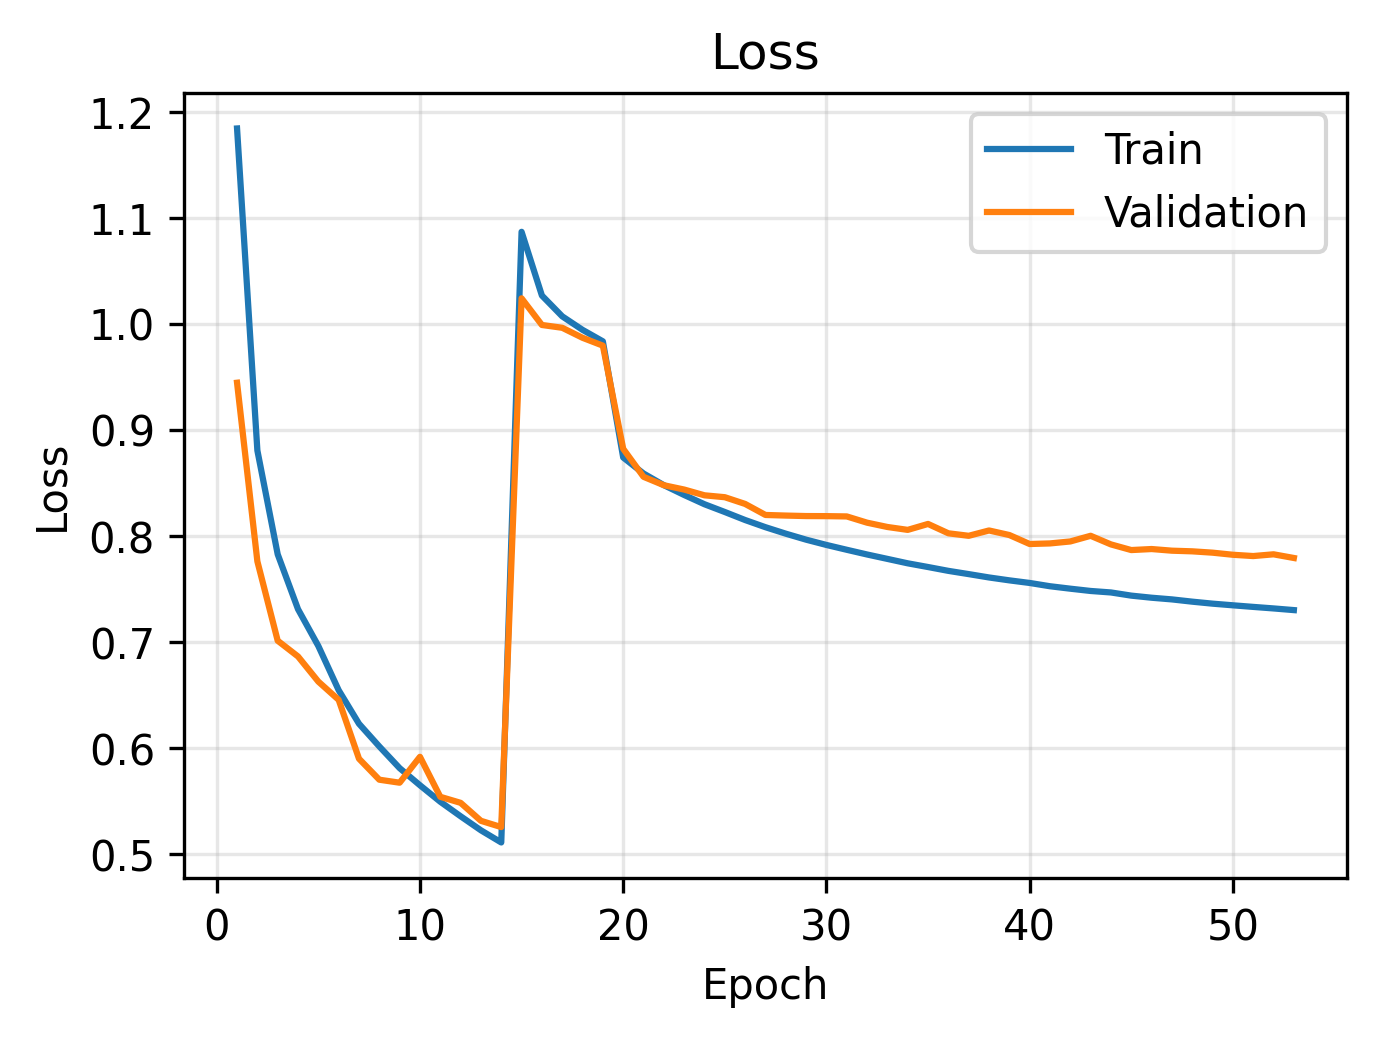

curve_miou


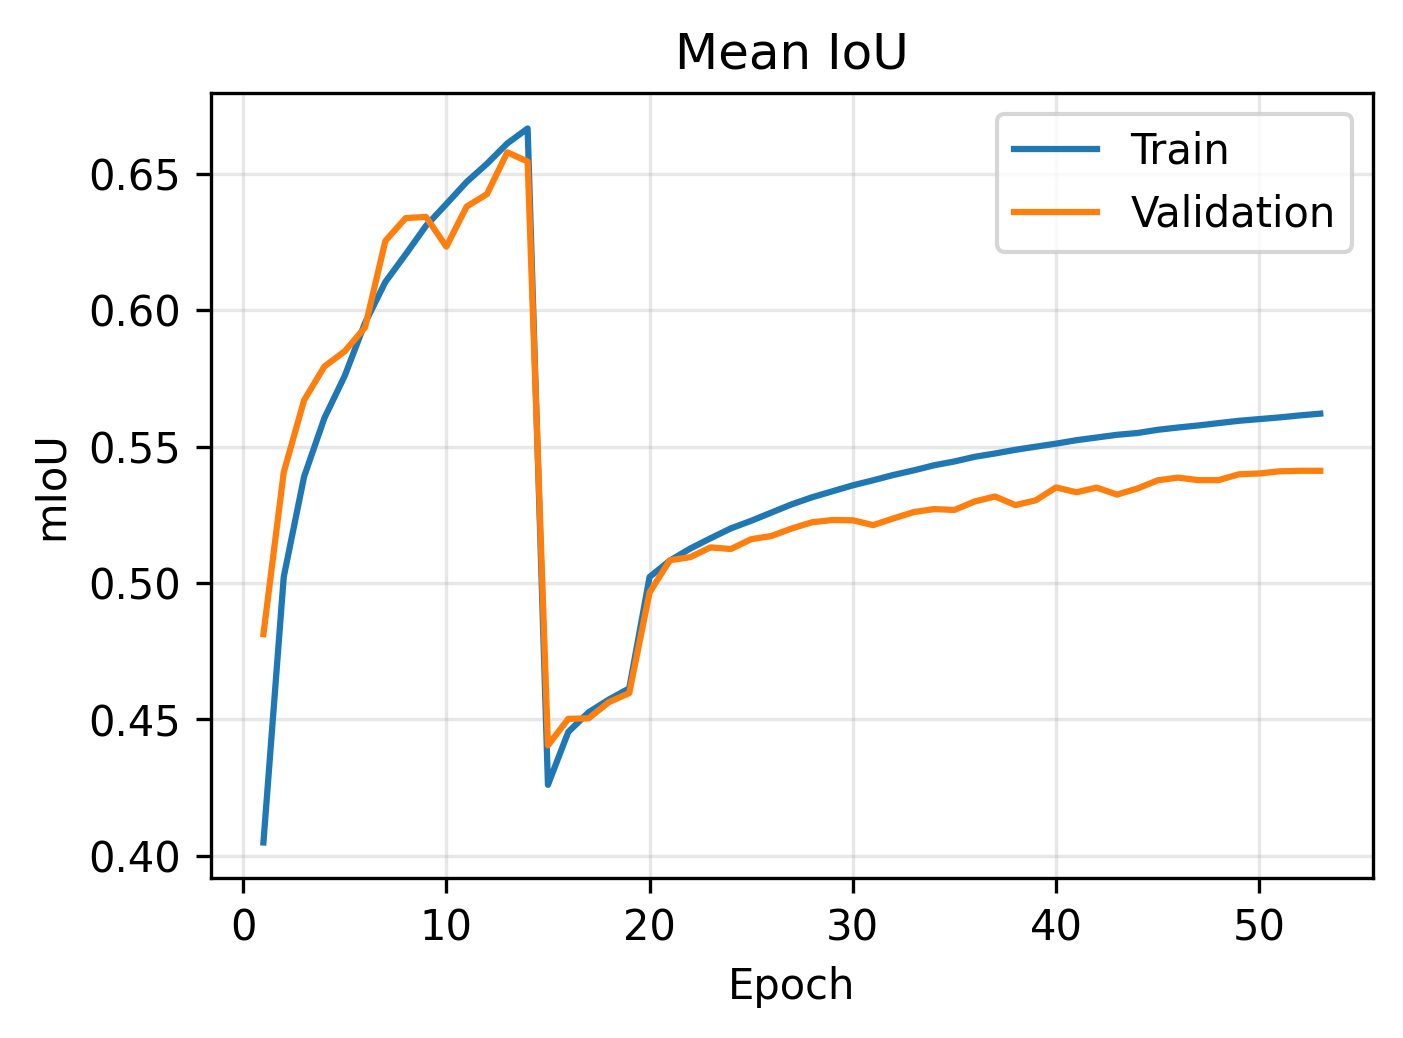

curve_macro_f1


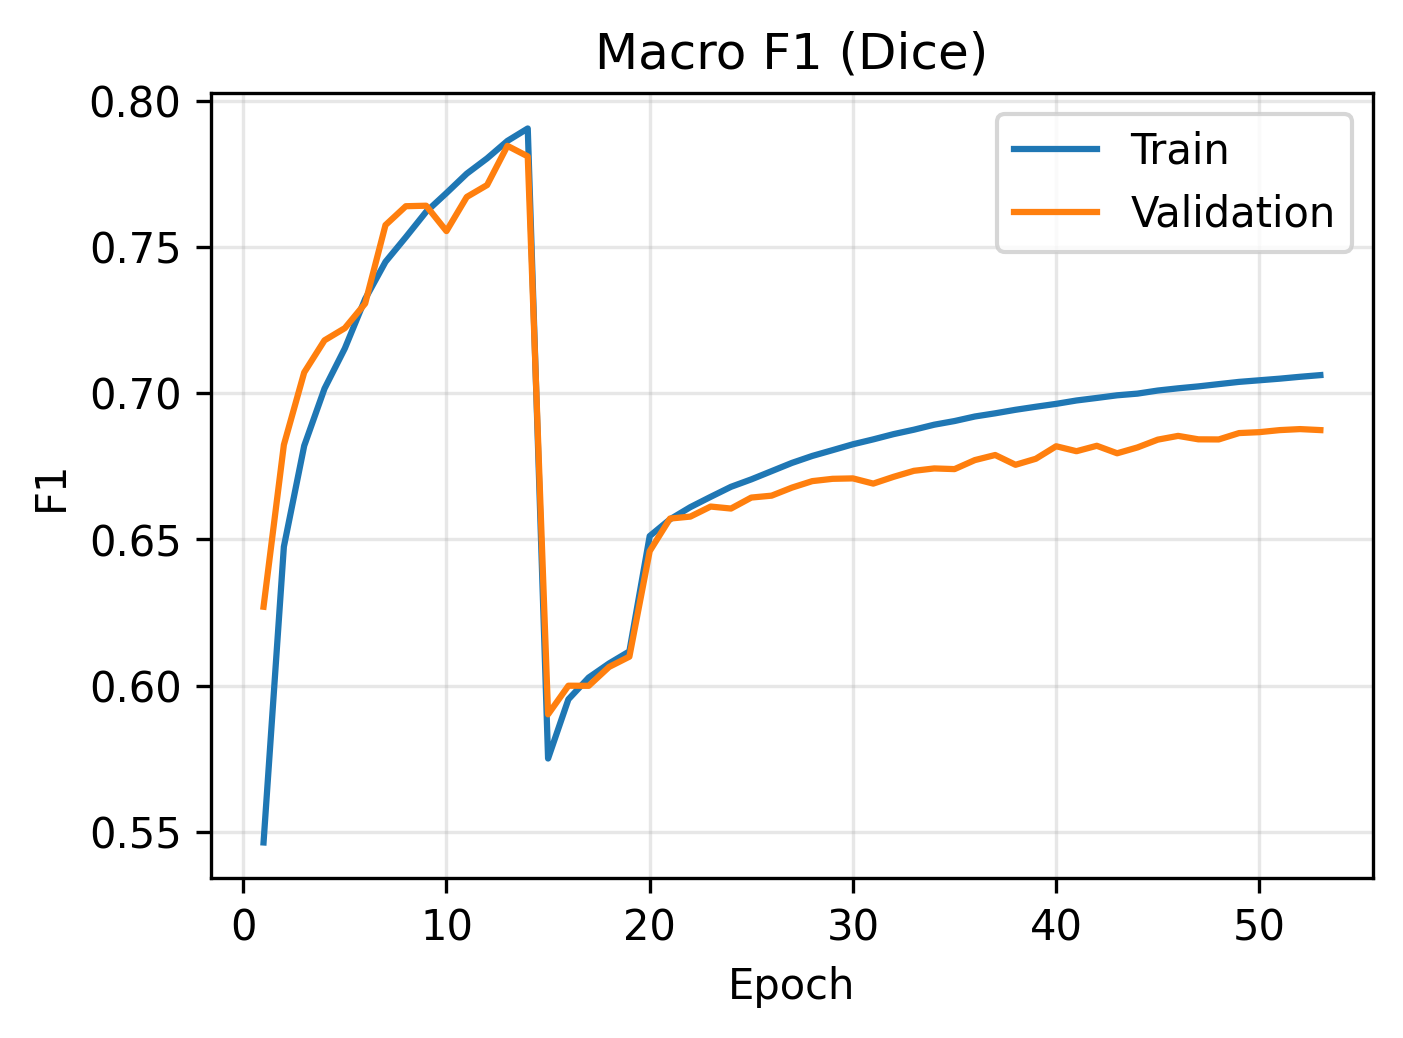

curve_lr


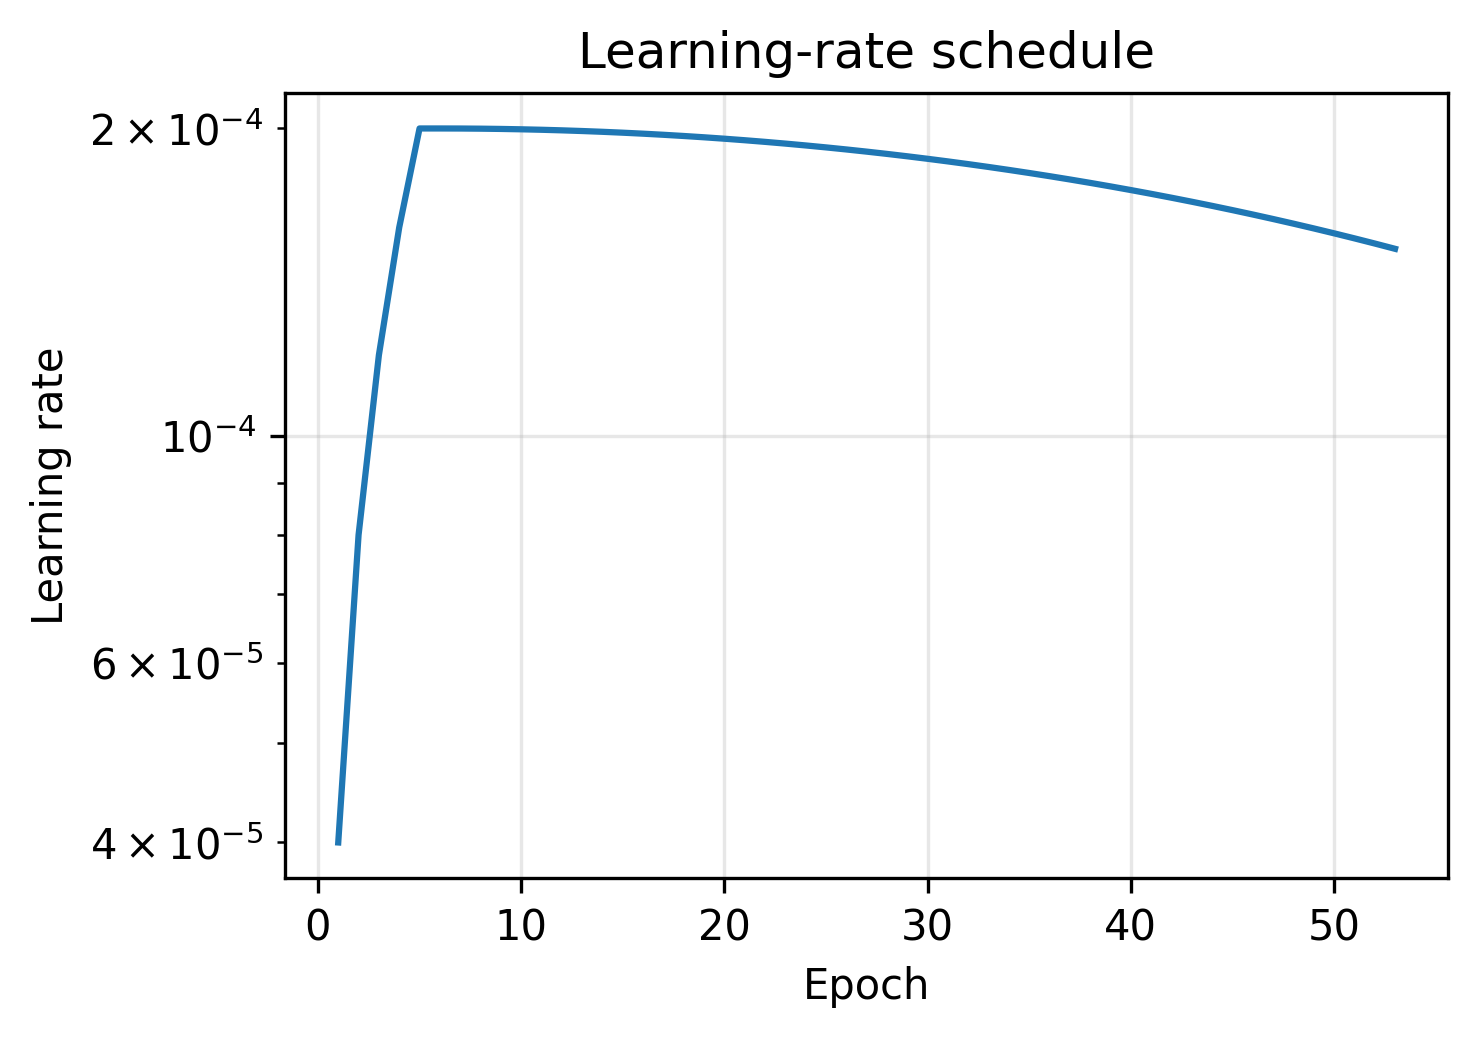

test_confusion_normalized


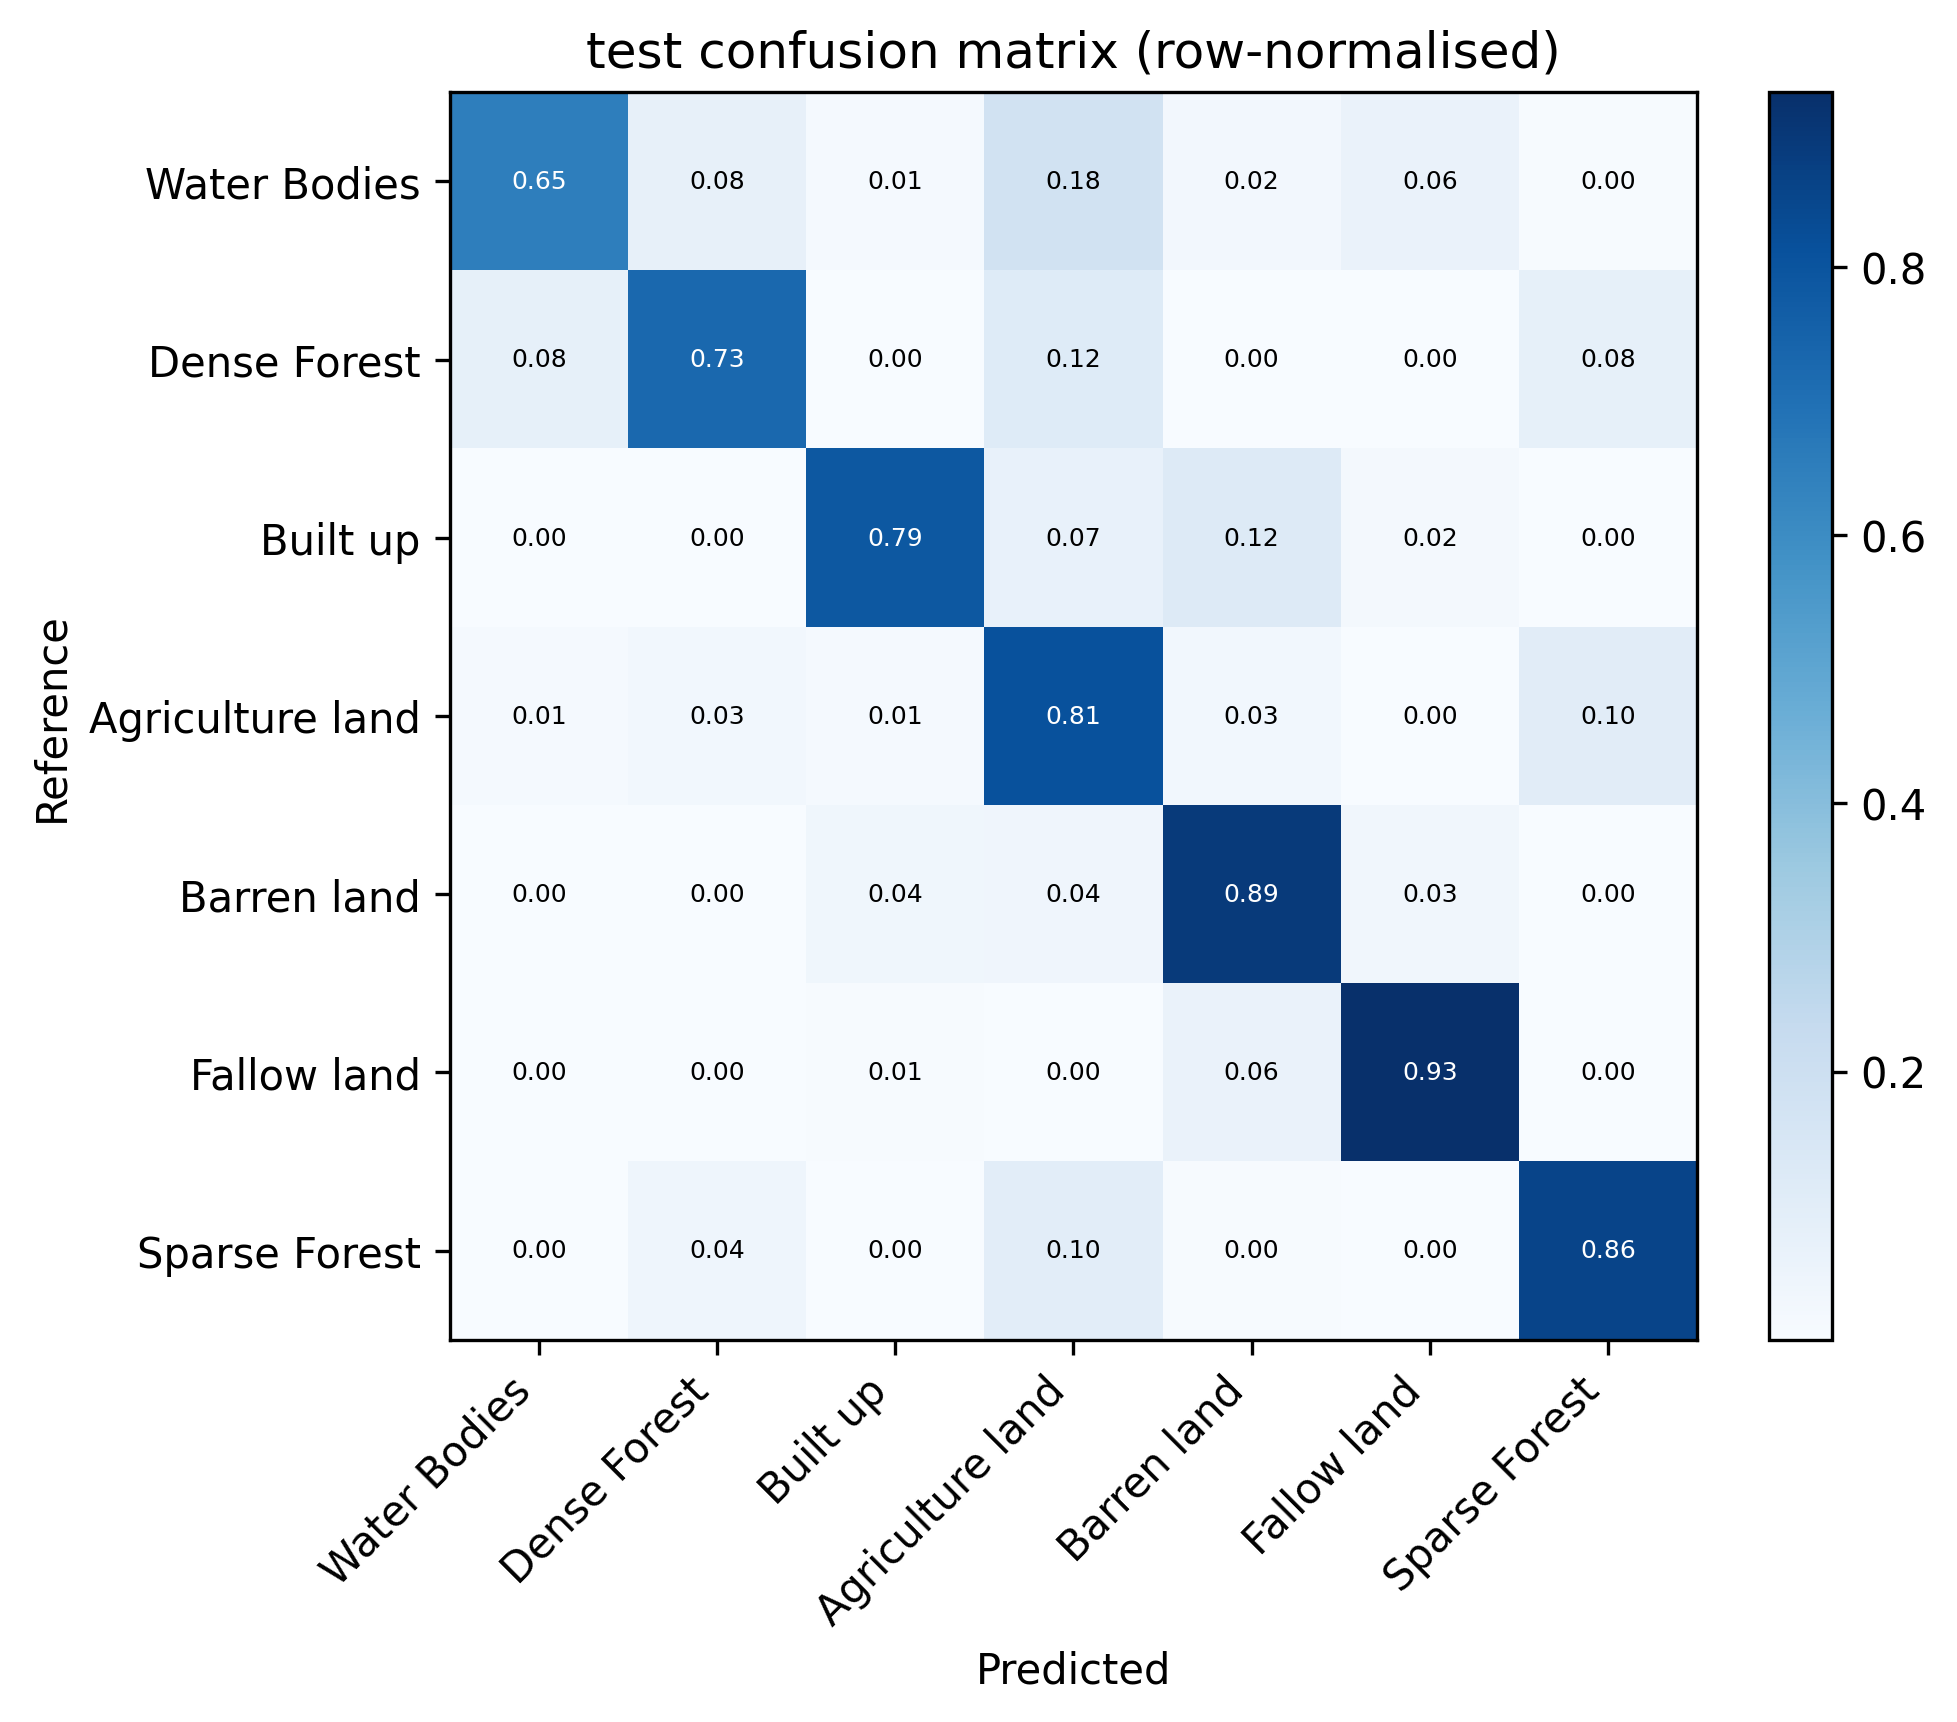

test_per_class_iou


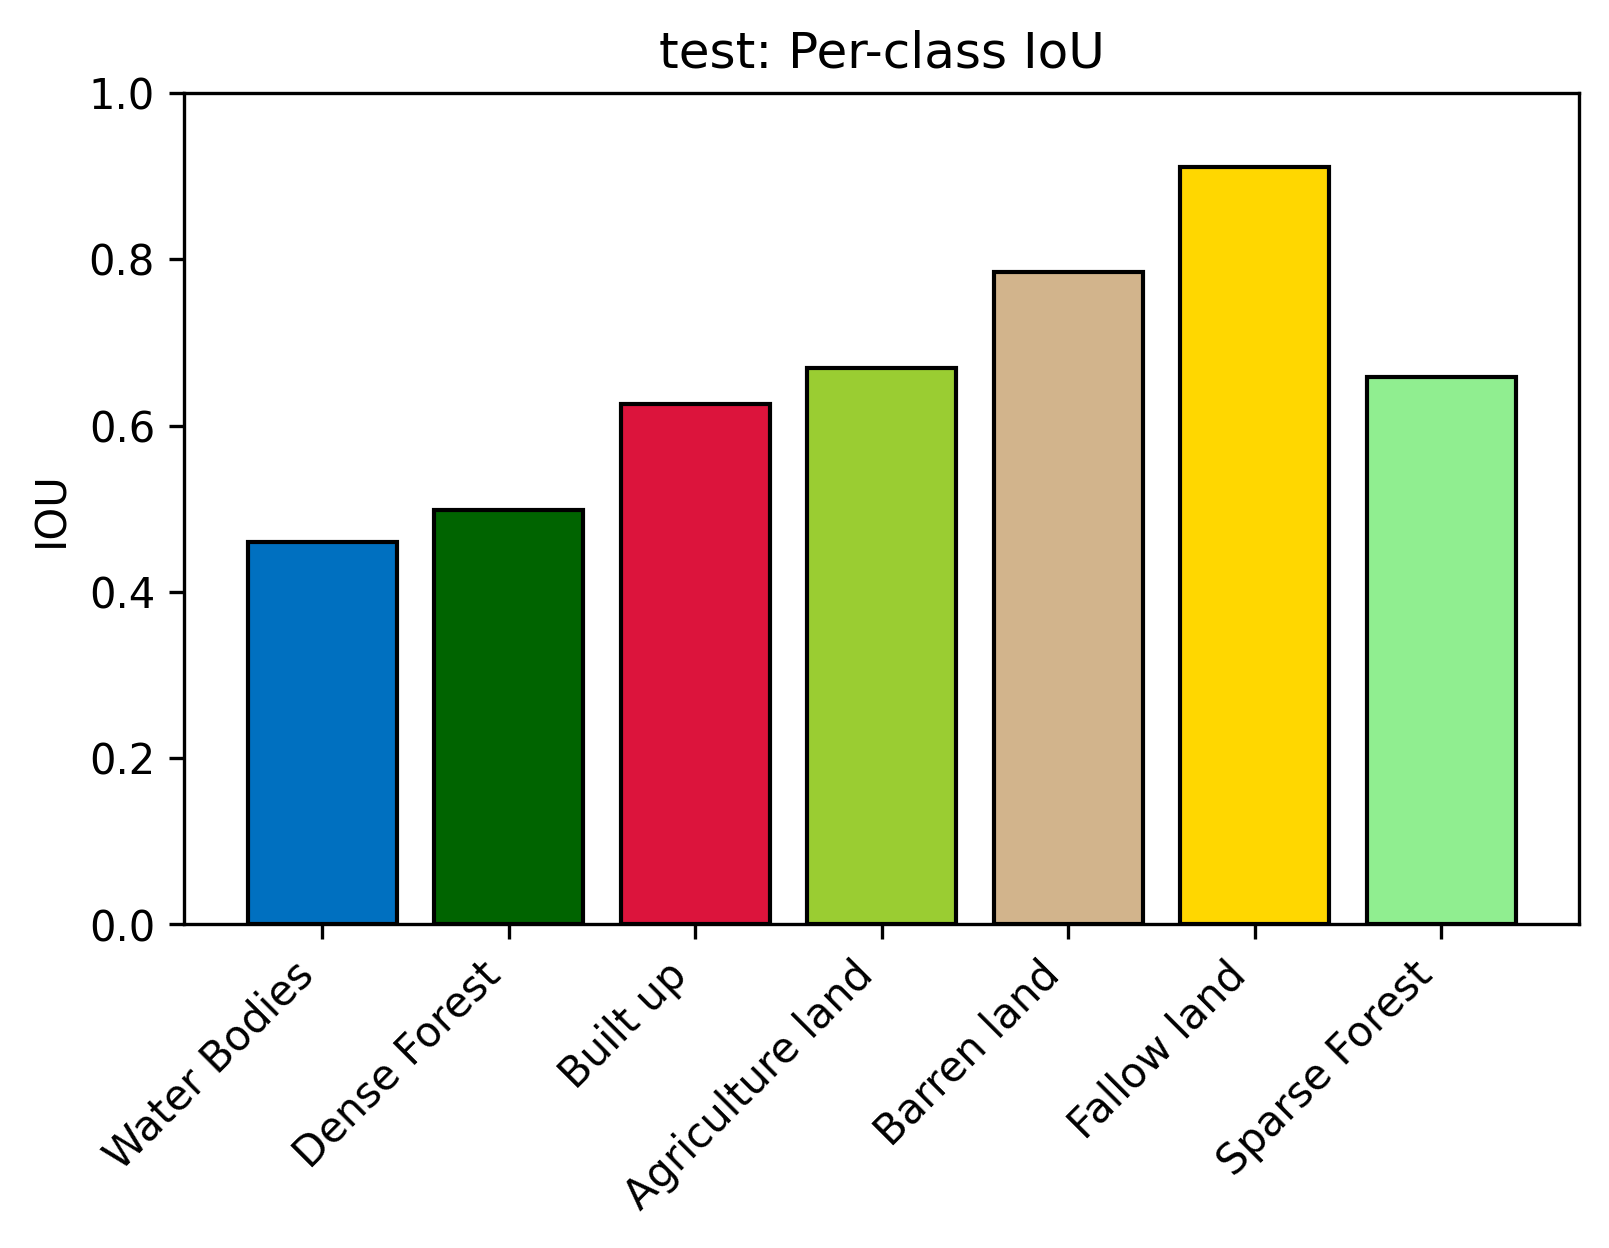

test_per_class_precision_recall


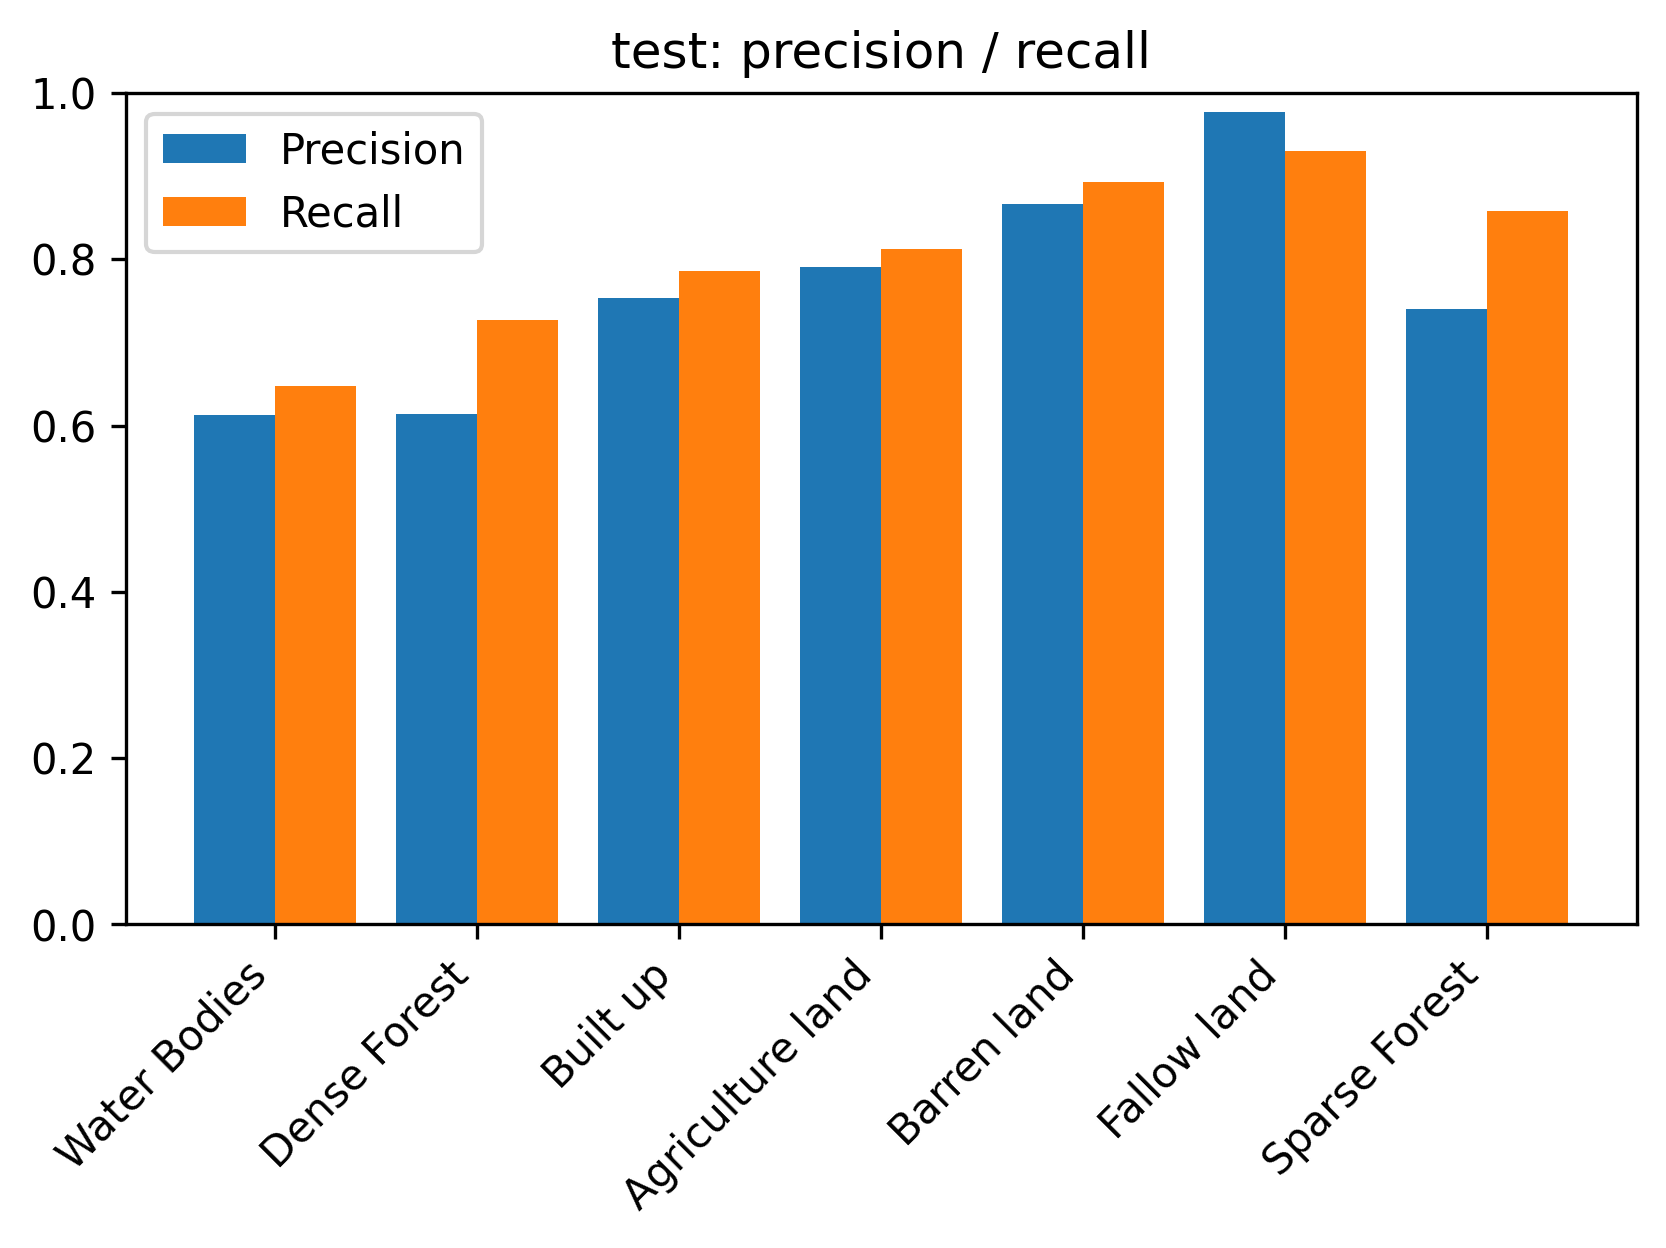

['curve_loss.eps', 'curve_loss.png', 'curve_lr.eps', 'curve_lr.png', 'curve_macro_f1.eps', 'curve_macro_f1.png', 'curve_miou.eps', 'curve_miou.png', 'legend.eps', 'legend.png', 'qualitative_examples.eps', 'qualitative_examples.png', 'test_confusion_normalized.eps', 'test_confusion_normalized.png', 'test_confusion_raw.eps', 'test_confusion_raw.png', 'test_per_class_f1_dice.eps', 'test_per_class_f1_dice.png', 'test_per_class_iou.eps', 'test_per_class_iou.png', 'test_per_class_precision_recall.eps', 'test_per_class_precision_recall.png', 'validation_confusion_normalized.eps', 'validation_confusion_normalized.png', 'validation_confusion_raw.eps', 'validation_confusion_raw.png', 'validation_per_class_f1_dice.eps', 'validation_per_class_f1_dice.png', 'validation_per_class_iou.eps', 'validation_per_class_iou.png', 'validation_per_class_precision_recall.eps', 'validation_per_class_precision_recall.png']


In [17]:
from IPython.display import Image as IPImage, display
fd = f"{c_main['exp_dir']}/figures"
for f in ["curve_loss", "curve_miou", "curve_macro_f1", "curve_lr", "test_confusion_normalized", "test_per_class_iou", "test_per_class_precision_recall"]:
    if os.path.exists(f"{fd}/{f}.png"): print(f); display(IPImage(f"{fd}/{f}.png", width=520))
print(sorted(os.listdir(fd)))

## 20. Qualitative results: strong / average / failure cases (selected by per-image mIoU rank, not by appearance)
Panels: RGB · reference · prediction · error map (white = correct, red = wrong, grey = ignored) · predictive entropy.

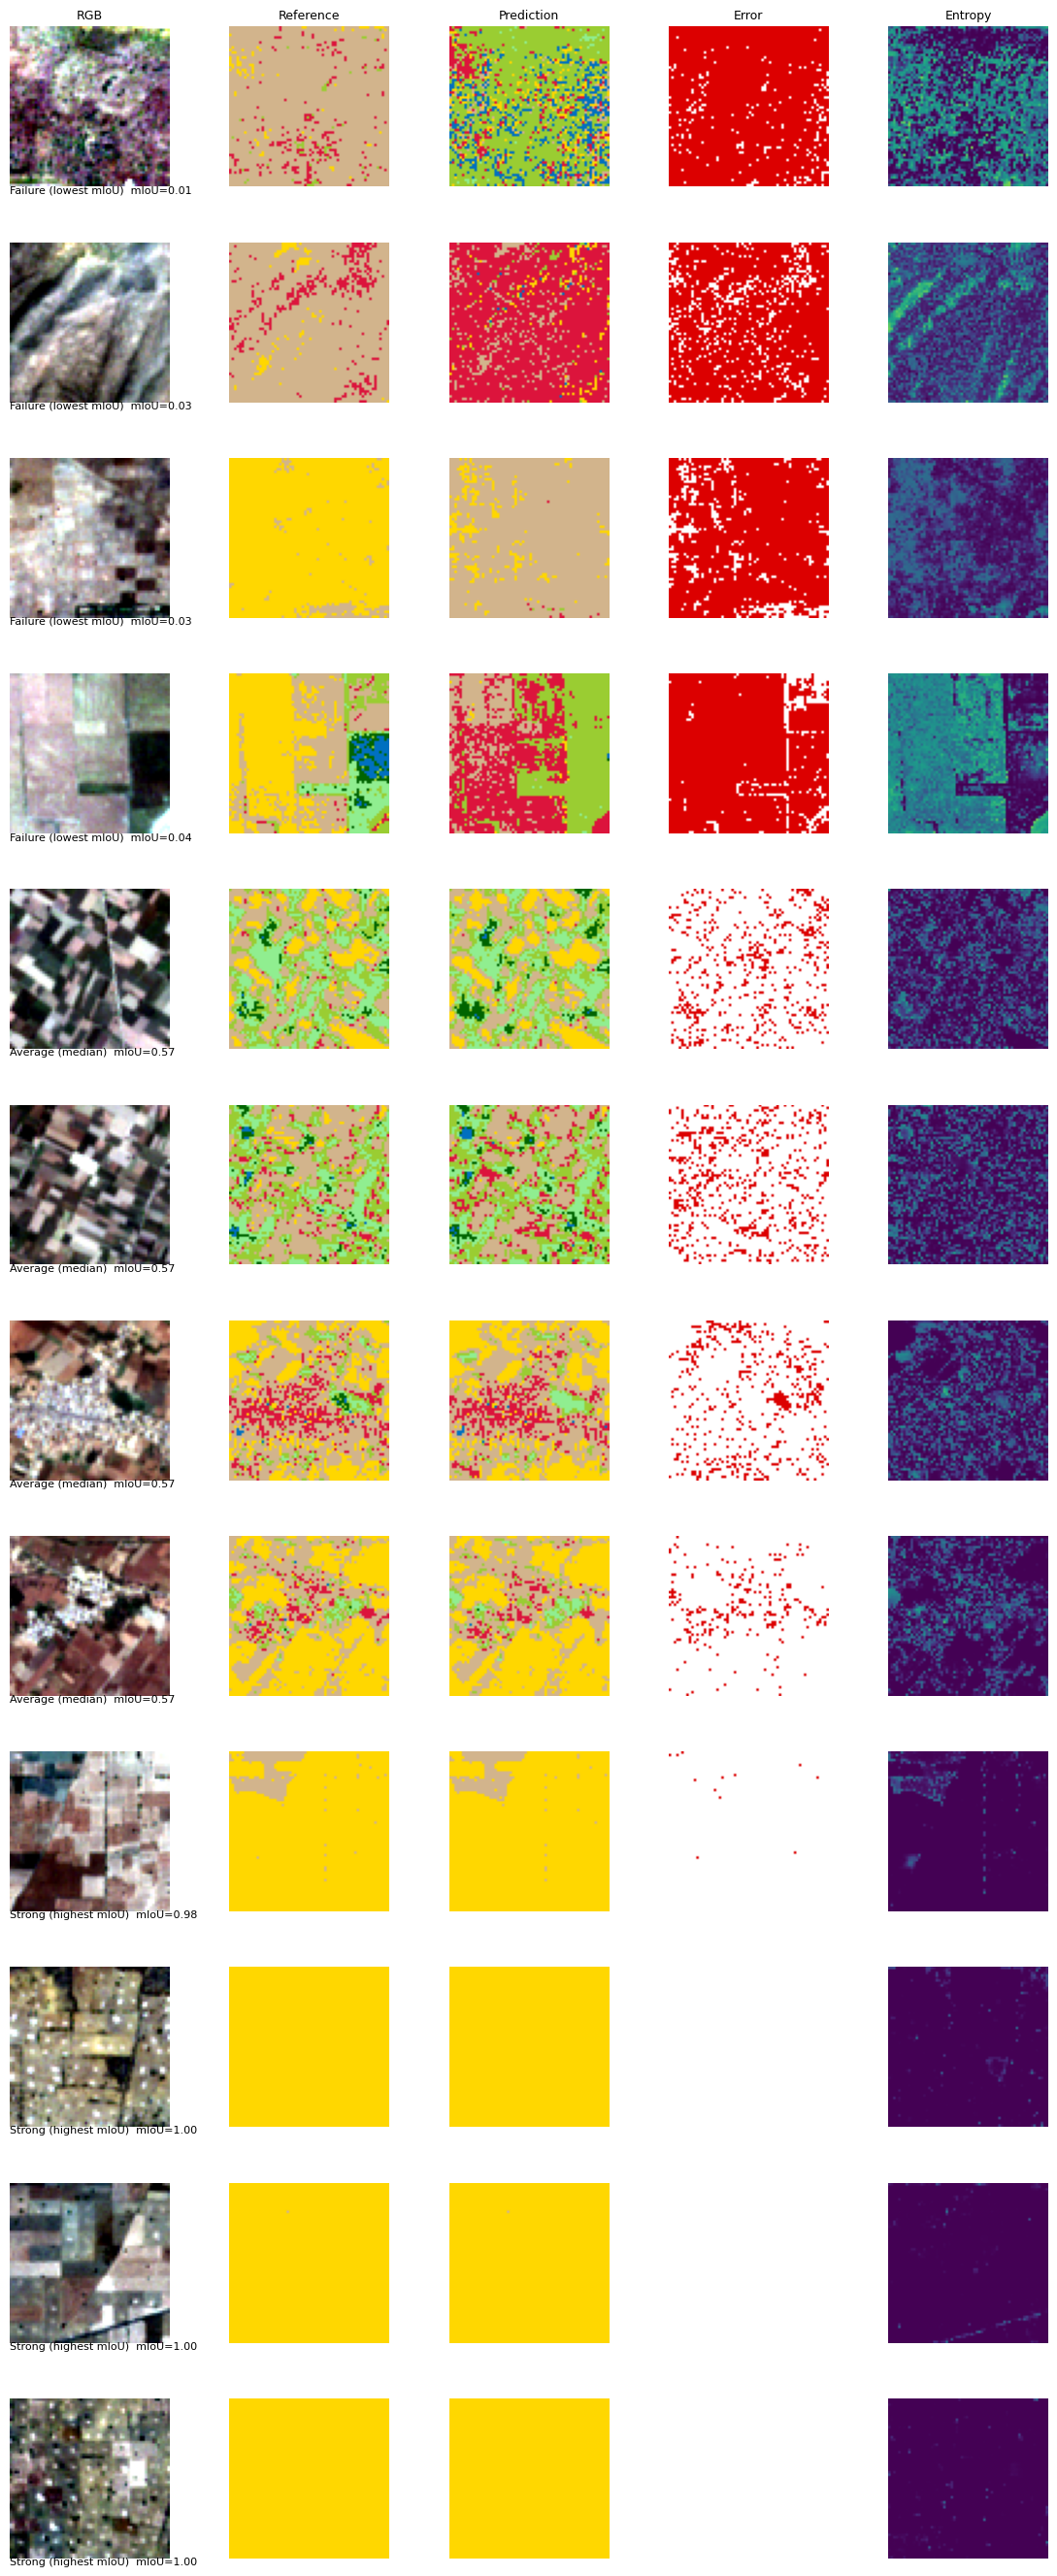

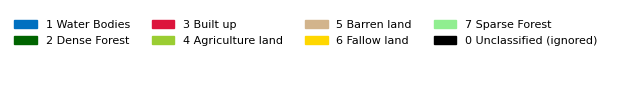

In [18]:
sys.path.insert(0, CODE); import importlib, common as Cm; importlib.reload(Cm)
import torch, matplotlib.pyplot as plt, torch.nn.functional as F
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
cfg_m = json.load(open(f"{c_main['exp_dir']}/config.json")); model, _ = Cm.build_model(cfg_m, pretrained=False)
ck = torch.load(f"{c_main['exp_dir']}/checkpoints/best.pt", map_location=dev, weights_only=False); model.load_state_dict(ck["model"]); model = model.to(dev).eval()
pi = pd.read_csv(f"{c_main['exp_dir']}/test_per_image_results.csv").dropna(subset=["iou"]).sort_values("iou").reset_index(drop=True)
pick = {"Failure (lowest mIoU)": pi.iloc[:4], "Average (median)": pi.iloc[len(pi)//2-2:len(pi)//2+2], "Strong (highest mIoU)": pi.iloc[-4:]}
ds = Cm.LULCDataset(f"{ROOT}/splits/test_manifest.csv", cfg_m, train=False); idmap = {v: i for i, v in enumerate(ds.df.id)}
fig, axs = plt.subplots(12, 5, figsize=(11, 27)); row = 0
for title, sub in pick.items():
    for _, r in sub.iterrows():
        x, y, _ = ds[idmap[r.image_id]]
        with torch.no_grad(): lg = model(x.unsqueeze(0).to(dev)).float()
        p = lg.softmax(1)[0]; pred = p.argmax(0).cpu().numpy(); ent = (-(p * (p + 1e-8).log()).sum(0) / np.log(7)).cpu().numpy(); gt = y.numpy()
        rgb = np.clip(x.numpy().transpose(1, 2, 0) * ds.std + ds.mean, 0, 1)
        err = np.full(gt.shape + (3,), 200, np.uint8); v = gt != 255; err[v & (pred == gt)] = 255; err[v & (pred != gt)] = (220, 0, 0)
        for j, (im, t) in enumerate([(rgb, "RGB"), (Cm.colorize(gt), "Reference"), (Cm.colorize(pred), "Prediction"), (err, "Error"), (ent, "Entropy")]):
            axs[row, j].imshow(im, vmin=0, vmax=1) if j == 4 else axs[row, j].imshow(im); axs[row, j].axis("off")
            if row == 0: axs[row, j].set_title(t, fontsize=9)
        axs[row, 0].text(0, -0.05, f"{title}  mIoU={r.iou:.2f}", transform=axs[row, 0].transAxes, fontsize=8, va="bottom"); row += 1
plt.tight_layout(); fig.savefig(f"{fd}/qualitative_examples.png", dpi=200, bbox_inches="tight"); fig.savefig(f"{fd}/qualitative_examples.eps", bbox_inches="tight"); plt.show()
from matplotlib.patches import Patch
fig2, ax2 = plt.subplots(figsize=(7, 1)); ax2.axis("off"); ax2.legend(handles=[Patch(color=np.array(Cm.CLASS_COLORS_SRC[i]) / 255, label=f"{i} {Cm.CLASS_NAMES_SRC[i]}") for i in range(1, 8)] + [Patch(color="black", label="0 Unclassified (ignored)")], ncol=4, frameon=False, fontsize=8)
fig2.savefig(f"{fd}/legend.png", dpi=300, bbox_inches="tight"); fig2.savefig(f"{fd}/legend.eps", bbox_inches="tight"); plt.show()
del model; torch.cuda.empty_cache()

## 21. Experiment summary & model-comparison table (built only from completed experiment files)

In [19]:
rows = []
for d in sorted(glob.glob(f"{ROOT}/experiments/*/")):
    name = os.path.basename(d.rstrip("/"))
    if any(t in name for t in ("_smokecfg", "_ddpsmoke", "_resumetest")): continue
    if not (os.path.exists(f"{d}runtime.json") and os.path.exists(f"{d}validation_metrics.csv")): continue
    rt = json.load(open(f"{d}runtime.json")); cf = json.load(open(f"{d}config.json")); v = pd.read_csv(f"{d}validation_metrics.csv").iloc[0]
    row = dict(experiment=name, model=cf["model"], encoder=cf["encoder"], pretrained=cf["pretrained"], loss=cf["loss"], lr=cf["lr"], scheduler=cf["scheduler"], aug=cf["augmentation"],
               params_M=rt["params_total"] / 1e6, best_epoch=rt["best_epoch"], epochs_run=rt["epochs_run"], val_OA=v.oa, val_mIoU=v.miou, val_macroF1=v.macro_f1, val_kappa=v.kappa,
               train_time_h=rt["train_time_s"] / 3600, peak_mem_MB=rt["peak_mem_mb_max"], GFLOPs_fwd=(rt["forward_flops_per_image"] or np.nan) / 1e9, effective_batch=rt["effective_batch"])
    if os.path.exists(f"{d}test_metrics.csv"):
        t = pd.read_csv(f"{d}test_metrics.csv").iloc[0]
        row.update(test_OA=t.oa, test_mIoU=t.miou, test_macroF1=t.macro_f1, test_kappa=t.kappa, inference_img_per_s=rt.get("inference_throughput_img_per_s"))
    rows.append(row)
summ = pd.DataFrame(rows); summ.to_csv(f"{ROOT}/model_comparisons/experiment_summary.csv", index=False); summ.to_csv(f"{ROOT}/experiments/experiment_summary.csv", index=False)
display(summ.round(4) if len(summ) else "No completed experiments yet.")
if len(summ) > 1:
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.4)); lab = summ.model + "\n" + summ.encoder
    for a, (col, t) in zip(ax, [("val_mIoU", "Validation mIoU"), ("params_M", "Parameters (M)"), ("train_time_h", "Training time (h)"), ("peak_mem_MB", "Peak GPU memory (MB)")]):
        a.bar(lab, summ[col]); a.set_title(t); plt.setp(a.get_xticklabels(), fontsize=7)
    plt.tight_layout(); [fig.savefig(f"{ROOT}/model_comparisons/comparison.{e}", dpi=300, bbox_inches="tight") for e in ("png", "eps")]; plt.show()
print("\nPART 2 COMPLETE. Part 3 (GeoTIFF inference, areas, flood-exposure utilities) follows as pasteable cells.")

,experiment,model,encoder,pretrained,loss,lr,scheduler,aug,params_M,best_epoch,...,val_kappa,train_time_h,peak_mem_MB,GFLOPs_fwd,effective_batch,test_OA,test_mIoU,test_macroF1,test_kappa,inference_img_per_s
0,sam2_semantic_hiera_bplus_seed42_20261013_035848,sam2_semantic,hiera_bplus,True,ce_dice,0.0002,warmup_cosine,moderate,69.6494,13,...,0.5452,6.5585,2712.5542,13.2442,64,0.8903,0.658,0.7847,0.837,270.1263



PART 2 COMPLETE. Part 3 (GeoTIFF inference, areas, flood-exposure utilities) follows as pasteable cells.


In [20]:
import os, sys, json, glob, time, shutil, zipfile, datetime, hashlib, platform, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
ROOT = "/kaggle/working/lulc_research"
SMOKE_TAGS = ("_smokecfg", "_ddpsmoke", "_resumetest")

def list_experiments(patterns):
    """All finished experiments (best.pt present), de-duplicated by name (first pattern wins). Selection metric = VALIDATION mIoU."""
    seen, rows = set(), []
    for pat in patterns:
        for ck in sorted(glob.glob(pat, recursive=True)):
            d = os.path.dirname(os.path.dirname(ck)); name = os.path.basename(d)
            if name in seen or any(t in name for t in SMOKE_TAGS): continue
            seen.add(name); r = dict(experiment=name, exp_dir=d, val_mIoU=np.nan, test_mIoU=np.nan)
            if os.path.exists(f"{d}/validation_metrics.csv"): r["val_mIoU"] = float(pd.read_csv(f"{d}/validation_metrics.csv").iloc[0].miou)
            if os.path.exists(f"{d}/test_metrics.csv"): r["test_mIoU"] = float(pd.read_csv(f"{d}/test_metrics.csv").iloc[0].miou)
            rows.append(r)
    return pd.DataFrame(rows)

if os.path.isdir(f"{ROOT}/experiments") and glob.glob(f"{ROOT}/experiments/*/checkpoints/best.pt"):
    ex = list_experiments([f"{ROOT}/experiments/*/checkpoints/best.pt"]).sort_values("val_mIoU", ascending=False)
    print(ex.drop(columns="exp_dir").to_string()); best = ex.iloc[0]; print("\nBEST by validation mIoU:", best.experiment)
    B = "/kaggle/working/lulc_deploy/lulc_research"; shutil.rmtree("/kaggle/working/lulc_deploy", ignore_errors=True)
    for sub in ("code", "preprocessing", "dataset_analysis"):
        os.makedirs(f"{B}/{sub}", exist_ok=True)
    for f in glob.glob(f"{ROOT}/code/*.py"): shutil.copy(f, f"{B}/code/")
    for f in glob.glob(f"{ROOT}/preprocessing/*.json"): shutil.copy(f, f"{B}/preprocessing/")
    for f in ("dataset_summary.json", "class_stats.json"):
        if os.path.exists(f"{ROOT}/dataset_analysis/{f}"): shutil.copy(f"{ROOT}/dataset_analysis/{f}", f"{B}/dataset_analysis/")
    dst = f"{B}/experiments/{best.experiment}"; os.makedirs(f"{dst}/checkpoints", exist_ok=True)
    shutil.copy(f"{best.exp_dir}/checkpoints/best.pt", f"{dst}/checkpoints/best.pt")
    for f in glob.glob(f"{best.exp_dir}/*.csv") + glob.glob(f"{best.exp_dir}/*.json"): shutil.copy(f, dst)
    shutil.copytree(f"{best.exp_dir}/figures", f"{dst}/figures", dirs_exist_ok=True)
    zp = "/kaggle/working/lulc_deploy_bundle.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for dp, _, fs in os.walk("/kaggle/working/lulc_deploy"):
            for f in fs: z.write(os.path.join(dp, f), os.path.relpath(os.path.join(dp, f), "/kaggle/working/lulc_deploy"))
    print(f"\nBundle written: {zp} ({os.path.getsize(zp)/2**20:.0f} MB)\nDownload it from the Output panel, then: Datasets > New Dataset > upload it (e.g. name 'lulc-deploy-bundle').")
else:
    print("No training outputs in this session -> skipping (normal for a NEW Part-3 notebook).")

                                         experiment  val_mIoU  test_mIoU
0  sam2_semantic_hiera_bplus_seed42_20261013_035848  0.317493   0.658027

BEST by validation mIoU: sam2_semantic_hiera_bplus_seed42_20261013_035848

Bundle written: /kaggle/working/lulc_deploy_bundle.zip (254 MB)
Download it from the Output panel, then: Datasets > New Dataset > upload it (e.g. name 'lulc-deploy-bundle').
